# Team number:66
# FULL names:<br>
1.Xiaolin Chen<br>
2.Irbrilyn Kieth Bien<br>
3.Yimin Chen<br>
4.WenShuo Yu<br>
5.Wen Shi Ng<br>
# Student ID numbers:<br>
1.48595020<br>
2.48689947<br>
3.45510385<br>
4.46817573<br>
5.48806366

Acknowledgement Statement by students: <br>
Please keep one acknowledgment from the following<br>
	I acknowledge that I have not used GenAI (e. g., ChatGPT) in drafting and proofreading of this assignment.<br>

# Answer to Section 1: Clean the dataset  (in this section, insert as many cells as needed) 

In [1]:
import pandas as pd              
import numpy as np               
import matplotlib.pyplot as plt  
import seaborn as sns            
from scipy.stats import ttest_ind 
import math

In [2]:
#Step 1: Load dataset 2023 & dataset 2024
df_2023 = pd.read_csv('2023.csv', encoding='latin-1', dtype=str, low_memory=False)
df_2024 = pd.read_csv('2024.csv', encoding='latin-1', dtype=str, low_memory=False)

In [3]:
#Step 2: Check the structure and details of both datasets
df_2023.info()
df_2024.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1037205 entries, 0 to 1037204
Data columns (total 38 columns):
 #   Column                    Non-Null Count    Dtype 
---  ------                    --------------    ----- 
 0   accounting_date           1037197 non-null  object
 1   fiscal_year               1037197 non-null  object
 2   fiscal_month              1037197 non-null  object
 3   company_code              1037197 non-null  object
 4   customer_code             986544 non-null   object
 5   customer_district_code    1037187 non-null  object
 6   item_code                 1037194 non-null  object
 7   business_area_code        1037197 non-null  object
 8   item_group_code           1037197 non-null  object
 9   item_class_code           1037197 non-null  object
 10  item_type                 1037197 non-null  object
 11  bonus_group_code          1037197 non-null  object
 12  environment_group_code    1037197 non-null  object
 13  technology_group_code     1037197 non-null

In [4]:
#Step 3:
# Drop empty columns in df_2023
df_2023 = df_2023.drop(columns=['item_source_class', 'dss_update_time'])
# Drop the duplicated & empty columns in df_2024
df_2024 = df_2024.drop(columns=['customer_order_number.1','item_source_class', 'dss_update_time'])

# Check
print(df_2023.shape)
print(df_2024.shape)

(1037205, 36)
(951177, 36)


In [5]:
#Step 4: Check missing value
df_2023 = df_2023.replace([' ','NA', 'Na', 'na', 'nan'], np.nan)
df_2024 = df_2024.replace([' ','NA', 'Na', 'na', 'nan'], np.nan)
print(df_2023.isna().sum())
print(df_2024.isna().sum())

accounting_date                 8
fiscal_year                     8
fiscal_month                    8
company_code                    8
customer_code               50661
customer_district_code         22
item_code                      11
business_area_code              8
item_group_code                 8
item_class_code                 8
item_type                       8
bonus_group_code                8
environment_group_code          8
technology_group_code           8
commission_group_code           8
reporting_classification        8
light_source                    8
warehouse_code                  8
abc_class_code                  8
abc_class_volume                8
business_chain_l1_code          8
business_chain_l1_name          8
contact_method_code             8
salesperson_code                8
order_type_code                 8
market_segment                  8
value_sales                     8
value_cost                      9
value_quantity                 13
value_price_ad

In [6]:
# drop column contain too much missing value
df_2023 = df_2023.drop(columns=['contact_method_code'])
df_2024 = df_2024.drop(columns=['contact_method_code'])

In [7]:
print(df_2023.nunique())
print(df_2024.nunique())

accounting_date                274
fiscal_year                      2
fiscal_month                    12
company_code                     9
customer_code                 3226
customer_district_code          16
item_code                    25107
business_area_code              28
item_group_code                560
item_class_code                197
item_type                        9
bonus_group_code                 2
environment_group_code           9
technology_group_code           97
commission_group_code            3
reporting_classification         2
light_source                     3
warehouse_code                  55
abc_class_code                  10
abc_class_volume                10
business_chain_l1_code          42
business_chain_l1_name          39
salesperson_code               253
order_type_code                 36
market_segment                   1
value_sales                  85145
value_cost                  197061
value_quantity                1527
value_price_adjustme

In [8]:
#Step 5: Convert attributes to correct datatype

# Define column groups
date_cols = ['accounting_date', 'invoice_date', 'order_date']
int_cols = ['fiscal_year', 'fiscal_month', 'line_number']
float_cols = ['value_sales', 'value_cost', 'value_quantity']

for data in [df_2023, df_2024]:
    # Convert date columns
    data[date_cols] = data[date_cols].apply(pd.to_datetime, errors='coerce')
    
    # Convert integer columns (nullable Int64 type)
    data[int_cols] = data[int_cols].apply(pd.to_numeric, errors='coerce').astype('Int64')
    
    # Convert float columns
    data[float_cols] = data[float_cols].apply(pd.to_numeric, errors='coerce')
    
    # Convert remaining columns to string, strip spaces, and convert to uppercase
    other_cols = data.columns.difference(date_cols + int_cols + float_cols)
    for col in other_cols:
        data[col] = data[col].apply(lambda x: str(x).strip() if pd.notna(x) else np.nan)

#check data type:
print(df_2023.dtypes)
print(df_2024.dtypes)
#check missing value:
print(df_2023.isna().sum())
print(df_2024.isna().sum())

accounting_date             datetime64[ns]
fiscal_year                          Int64
fiscal_month                         Int64
company_code                        object
customer_code                       object
customer_district_code              object
item_code                           object
business_area_code                  object
item_group_code                     object
item_class_code                     object
item_type                           object
bonus_group_code                    object
environment_group_code              object
technology_group_code               object
commission_group_code               object
reporting_classification            object
light_source                        object
warehouse_code                      object
abc_class_code                      object
abc_class_volume                    object
business_chain_l1_code              object
business_chain_l1_name              object
salesperson_code                    object
order_type_

In [9]:
#Step 7:Drop rows with too many NaNs (more than 35 columns affected)

for data in [df_2023, df_2024]:
    data = data[data.isnull().sum(axis = 1) < 19]

#Check dataset shapes after dropping
print(df_2023.shape)
print(df_2024.shape)

(1037205, 35)
(951177, 35)


In [10]:
# Step 9: Fill selected columns with 'Unknown' for missing values and drop rows with too many 'Unknown's

cols_missing = [
    'accounting_date', 'invoice_date', 'order_date', 'fiscal_year', 'fiscal_month', 
    'line_number', 'customer_district_code', 'item_code', 'company_code',
    'business_area_code', 'item_group_code', 'item_class_code', 'item_type',
    'bonus_group_code', 'environment_group_code', 'commission_group_code', 
    'reporting_classification', 'light_source', 'warehouse_code', 'abc_class_code',
    'abc_class_volume', 'salesperson_code', 'order_type_code', 'market_segment', 
    'value_sales', 'value_cost', 'value_quantity', 'currency','accounting_date', 
    'invoice_date', 'order_date', 'customer_order_number', 'invoice_number'
]

for df in [df_2023, df_2024]:
    # Fill missing values of customer_code with 'Unknown'
    df['customer_code'] = df['customer_code'].fillna('Unknown')
    df['technology_group_code'] = df['technology_group_code'].fillna('Unknown')
    # Drop other missing values
    df.dropna(subset = cols_missing, inplace=True)
    

#check shapes after filtering
print(df_2023.shape)
print(df_2024.shape)

(1031771, 35)
(951043, 35)


In [11]:
print(df_2023.isna().sum())
print(df_2024.isna().sum())

accounting_date              0
fiscal_year                  0
fiscal_month                 0
company_code                 0
customer_code                0
customer_district_code       0
item_code                    0
business_area_code           0
item_group_code              0
item_class_code              0
item_type                    0
bonus_group_code             0
environment_group_code       0
technology_group_code        0
commission_group_code        0
reporting_classification     0
light_source                 0
warehouse_code               0
abc_class_code               0
abc_class_volume             0
business_chain_l1_code       0
business_chain_l1_name       0
salesperson_code             0
order_type_code              0
market_segment               0
value_sales                  0
value_cost                   0
value_quantity               0
value_price_adjustment      57
currency                     0
invoice_number               0
line_number                  0
invoice_

In [12]:
#Step 10:Standardize all string columns (strip spaces)

def clean_strings(df):
    for col in df.select_dtypes(include='object').columns:
        df[col] = df[col].astype(str).str.strip()
    return df

# Apply to both datasets
df_2023 = clean_strings(df_2023)
df_2024 = clean_strings(df_2024)

#check 
print(df_2023.shape)
print(df_2024.shape)

(1031771, 35)
(951043, 35)


In [13]:
#Step 11:Check unique values and value counts for categorical columns

# Function to check unique values and top counts
def check_unique_and_values(df, year):
    print(f"Checking {year}\n")
    # Identify categorical/object columns
    cat_cols = df.select_dtypes(include='object').columns
    for col in cat_cols:
        print(f"Column: {col} | Unique values: {df[col].nunique()}")
        print("Top 20 value counts:")
        print(df[col].value_counts(dropna=False).head(20))
        print("\n")
# Apply function to both datasets
check_unique_and_values(df_2023, 2023)
check_unique_and_values(df_2024, 2024)

Checking 2023

Column: company_code | Unique values: 9
Top 20 value counts:
company_code
205    661753
101    212093
220     83313
950     50427
100     19904
140      3584
510       349
240       283
170        65
Name: count, dtype: int64


Column: customer_code | Unique values: 3225
Top 20 value counts:
customer_code
Unknown       50428
469500002     32708
719001202      5791
1050400200     5699
604200400      4911
277691002      4761
942001658      4121
1802000200     4036
605801600      3652
537201402      3226
722000844      3059
622001426      2578
942300004      2316
1221821408     2293
554001602      2174
722000802      2167
1802000204     2165
629200800      2123
598961440      2049
599001034      2032
Name: count, dtype: int64


Column: customer_district_code | Unique values: 16
Top 20 value counts:
customer_district_code
300    229035
200    228742
400    176675
500     94228
600     86377
720     46085
410     37641
210     36690
540     25844
310     17449
710     15857
5

In [14]:
# 查看value_price_adjustment对应的value_sales，value_cost和value_quantity，看是否有规律可填
price_adj = df_2024.loc[df["value_price_adjustment"] == '1', ["value_sales", "value_cost", "value_quantity", "value_price_adjustment"]]

price_adj

,value_sales,value_cost,value_quantity,value_price_adjustment
112,-1.36,0.0,0.0,1
155,-2.80,0.0,0.0,1
228,-56.40,0.0,0.0,1
229,-0.86,0.0,0.0,1
293,-4.68,0.0,0.0,1
...,...,...,...,...
950778,-7.57,0.0,0.0,1
950900,-362.40,0.0,0.0,1
950917,-124.96,0.0,0.0,1
951016,-259.50,0.0,0.0,1


In [15]:
# value_cost和value_quantity为0时，value_price_adjustment记为1，其他情况记为0 
for df in [df_2023, df_2024]: 
    df["value_price_adjustment"] = '0'
    df.loc[(df["value_cost"] == 0) & (df["value_quantity"] == 0), "value_price_adjustment"] = '1'

In [16]:
df_2024[df_2024.isna().any(axis=1)][['business_chain_l1_code', 'business_chain_l1_name']]

,business_chain_l1_code,business_chain_l1_name


In [17]:
unique_pairs = df_2024[['business_chain_l1_code', 'business_chain_l1_name']].drop_duplicates().sort_values(by='business_chain_l1_name')

unique_pairs

,business_chain_l1_code,business_chain_l1_name
14638,Z850339,Active Electric Solutions
68,AEG,Aussie Energy Group
11365,Z6100,Beacon Lighting Supplies
83,BPS,BrightPower Solutions
181,ZZ1,Builders Supply Network
14836,CET,CetraPro Distributors
103,ZZ6,Constructor Supplies
19897,ZZ9,Corporate Builders Consortium
84108,Z8100,Corporate HQ Solutions
5439,Z3500,Corys Energy Systems


In [18]:
df_2024.loc[df_2024["business_chain_l1_name"] == "Independent Retailers Association", "business_chain_l1_code"] = "ZZ2"
df_2024.loc[df_2024["business_chain_l1_code"] == "ZZ2", "business_chain_l1_name"] = "Independent Retailers Association"
df_2024.loc[df_2024["business_chain_l1_code"] == "MED", "business_chain_l1_name"] = "Metro Electrical Distributors"
df_2024.loc[df_2024["business_chain_l1_code"] == "BPS", "business_chain_l1_name"] = "BrightPower Solutions"
df_2024.loc[df_2024["business_chain_l1_code"] == "ZZ3", "business_chain_l1_name"] = "ProLighting Specialists"

In [19]:
print(df_2023.isna().sum())
print(df_2024.isna().sum())

accounting_date             0
fiscal_year                 0
fiscal_month                0
company_code                0
customer_code               0
customer_district_code      0
item_code                   0
business_area_code          0
item_group_code             0
item_class_code             0
item_type                   0
bonus_group_code            0
environment_group_code      0
technology_group_code       0
commission_group_code       0
reporting_classification    0
light_source                0
warehouse_code              0
abc_class_code              0
abc_class_volume            0
business_chain_l1_code      0
business_chain_l1_name      0
salesperson_code            0
order_type_code             0
market_segment              0
value_sales                 0
value_cost                  0
value_quantity              0
value_price_adjustment      0
currency                    0
invoice_number              0
line_number                 0
invoice_date                0
customer_o

In [20]:
def business_name_code(df):
    ## 找出 business chain 哪些 name 对应多个 code
    name_with_multiple_codes = (
        df.groupby("business_chain_l1_name")["business_chain_l1_code"]
        .nunique()
    )
    name_with_multiple_codes = name_with_multiple_codes[name_with_multiple_codes > 1].index
    
    ## 保留这些 name 的行
    filtered = df[df["business_chain_l1_name"].isin(name_with_multiple_codes)]

    # 统计每个 (name, code) 出现次数
    result = (
        filtered.groupby(["business_chain_l1_name", "business_chain_l1_code"])
        .size()
        .reset_index(name="count")
        .sort_values(["business_chain_l1_name", "count"], ascending=[True, False])
    )

    return result
    
print(business_name_code(df_2023))
print("---------------------------------------")
print(business_name_code(df_2024))

       business_chain_l1_name business_chain_l1_code  count
1       General Suppliers Pty                    ZZZ  33521
0       General Suppliers Pty                    ZZ5   1067
2  Ideal Electrical Solutions                  Z2000   2475
3  Ideal Electrical Solutions                 ZI2000    325
4       PowerHub Distribution                  Z4500   2958
5       PowerHub Distribution                 ZI4500    284
---------------------------------------
       business_chain_l1_name business_chain_l1_code  count
0        Corys Energy Systems                  Z3500   2849
1        Corys Energy Systems                 ZI3500     18
3       General Suppliers Pty                    ZZZ  28897
2       General Suppliers Pty                    ZZ5    791
4  Ideal Electrical Solutions                  Z2000   2193
5  Ideal Electrical Solutions                  ZA200    112
6  Ideal Electrical Solutions                 ZI2000     98
7       PowerHub Distribution                  Z4500   3164


In [21]:
df_2023.loc[df_2023["business_chain_l1_name"] == "General Suppliers Pty", "business_chain_l1_code"] = "ZZZ"
df_2023.loc[df_2023["business_chain_l1_name"] == "Ideal Electrical Solutions", "business_chain_l1_code"] = "Z2000"
df_2023.loc[df_2023["business_chain_l1_name"] == "PowerHub Distribution", "business_chain_l1_code"] = "2958"
df_2024.loc[df_2024["business_chain_l1_name"] == "Corys Energy Systems", "business_chain_l1_code"] = "2849"
df_2024.loc[df_2024["business_chain_l1_name"] == "General Suppliers Pty", "business_chain_l1_code"] = "ZZZ"
df_2024.loc[df_2024["business_chain_l1_name"] == "Ideal Electrical Solutions", "business_chain_l1_code"] = "Z2000"
df_2024.loc[df_2024["business_chain_l1_name"] == "PowerHub Distribution", "business_chain_l1_code"] = "Z4500"

In [22]:
#Step 13: Check fiscal_month & Clean fiscal_month column and remove invalid months
def check_fiscal_month(df, year):
    print(f"Fiscal Month Check for {year}")
    print(f"Data type: {df['fiscal_month'].dtype}")
    print(f"Unique values: {sorted(df['fiscal_month'].dropna().unique())}")
    print(df['fiscal_month'].value_counts(dropna=False).sort_index())
    print(f"Missing values: {df['fiscal_month'].isna().sum()}")
    print("-" * 50)

# Convert fiscal_month to numeric (force errors to NaN)
df_2023['fiscal_month'] = pd.to_numeric(df_2023['fiscal_month'], errors='coerce')
df_2024['fiscal_month'] = pd.to_numeric(df_2024['fiscal_month'], errors='coerce')

# Keep only valid fiscal months 1–12
df_2023 = df_2023[df_2023['fiscal_month'].between(1, 12)]
df_2024 = df_2024[df_2024['fiscal_month'].between(1, 12)]

# Optional: reset index
df_2023.reset_index(drop=True, inplace=True)
df_2024.reset_index(drop=True, inplace=True)

# Re-check results
check_fiscal_month(df_2023, 2023)
check_fiscal_month(df_2024, 2024)

Fiscal Month Check for 2023
Data type: Int64
Unique values: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12)]
fiscal_month
1      96489
2      96529
3      80323
4      85274
5      82674
6      58864
7      76228
8      85890
9      88482
10     78891
11    108884
12     93243
Name: count, dtype: Int64
Missing values: 0
--------------------------------------------------
Fiscal Month Check for 2024
Data type: Int64
Unique values: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12)]
fiscal_month
1      98278
2      87636
3      80669
4      81667
5      70643
6      54256
7      62771
8      70574
9      74191
10     82752
11    104363
12     83238
Name: count, dtype: Int64
Missing values: 0
--------------------------------------------------


In [23]:
#Step 14 :Define the list of "Do Not Use" order type codes
do_not_use_codes = [
    'EDS', 'OBS', 'PPD', 'PM0', 'PGS', 'SPL', 'ZOP', 'ZC2', '5TN', 'PPO', 'ZD3', 'CSO'
]

# Drop rows in place for both datasets
df_2023 = df_2023[~df_2023['order_type_code'].isin(do_not_use_codes)]
df_2024 = df_2024[~df_2024['order_type_code'].isin(do_not_use_codes)]

# Check
print(df_2023['order_type_code'].nunique())
print(df_2024['order_type_code'].nunique())

24
25


In [24]:
#Step 15 :Replace 'AUS' with 'AUD' in the currency column
for df in [df_2023, df_2024]:
    df.loc[:, 'currency'] = df['currency'].replace('AUS', 'AUD')
# Check
print(df_2023['currency'].nunique())
print(df_2024['currency'].nunique())

5
4



YEAR 2023: Initial Outlier Summary 


,item_type,lower_outliers,upper_outliers,total_outliers
0,5,2283,27799,30082
1,1,448,11910,12358
2,7,4991,57559,62550
3,8,57,497,554
4,6,1614,15112,16726
5,4,157,1533,1690
6,2,12,461,473
7,9,256,2684,2940
8,3,35,267,302



 YEAR 2023: Skewness Summary 


,item_type,skewness
0,5,0.940
1,1,1.063
2,7,0.888
3,8,0.879
4,6,0.855
5,4,0.886
6,2,1.095
7,9,0.760
8,3,0.864


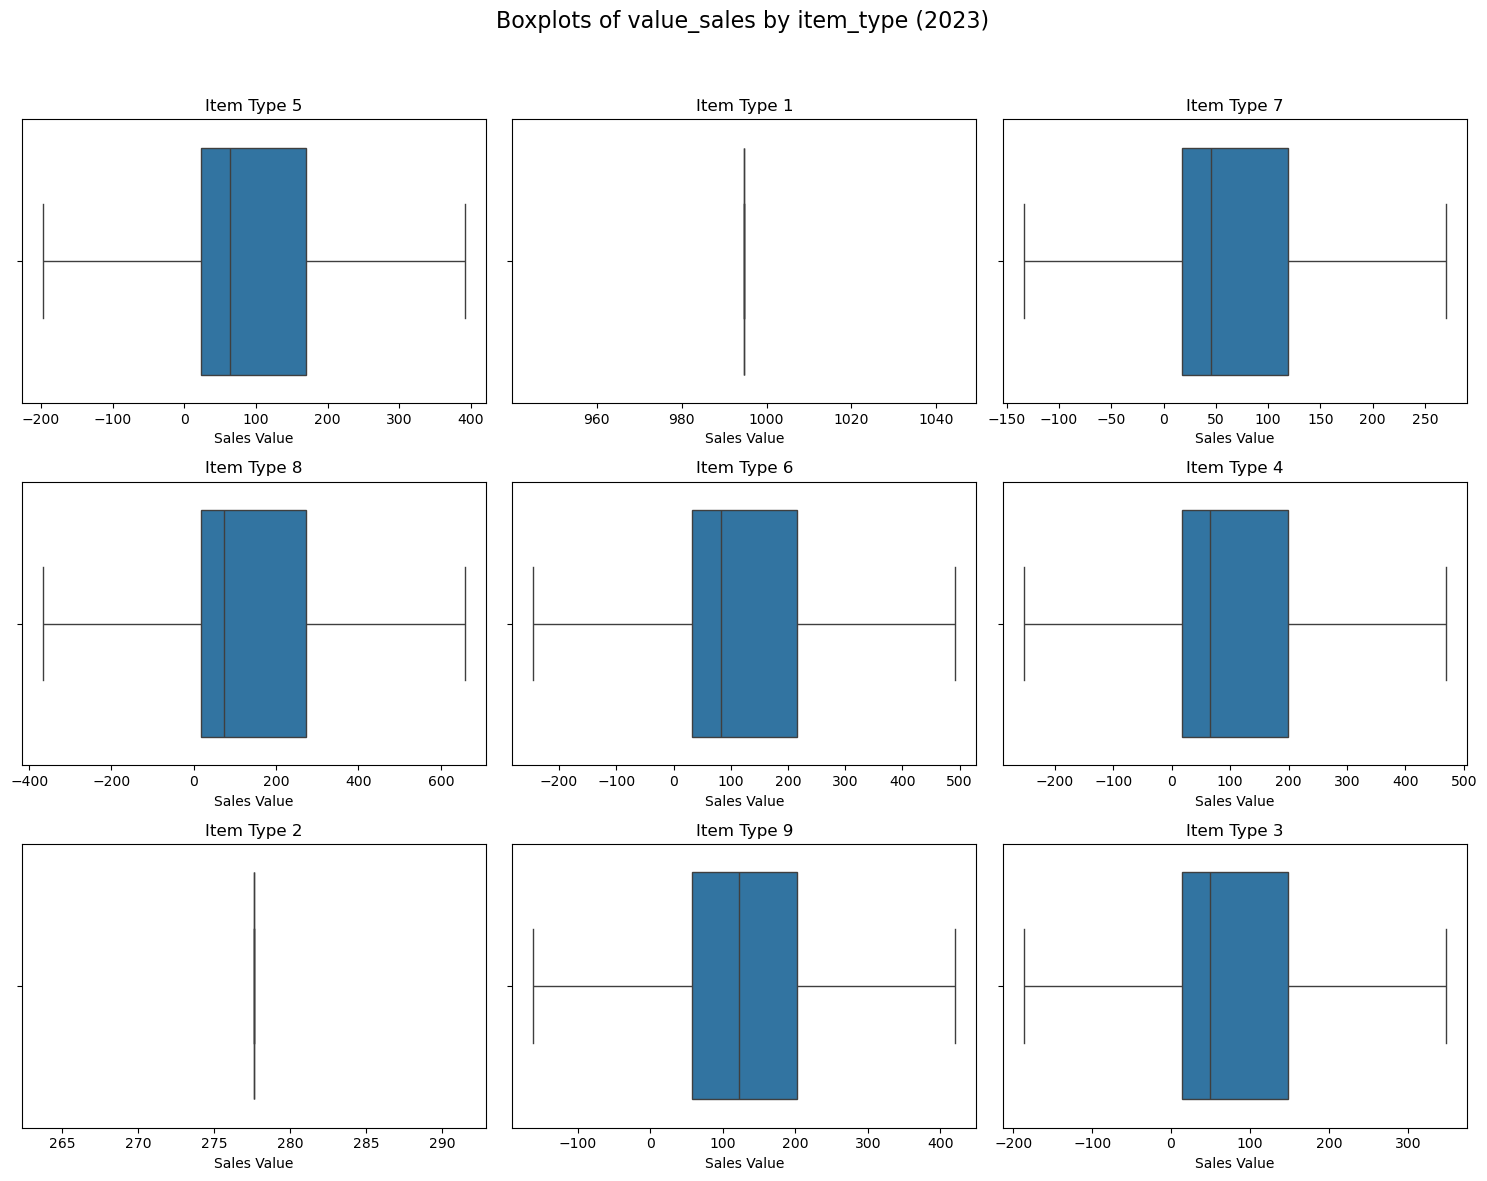


YEAR 2024: Initial Outlier Summary 


,item_type,lower_outliers,upper_outliers,total_outliers
0,5,1985,23762,25747
1,7,4607,53924,58531
2,6,1745,16602,18347
3,4,111,1368,1479
4,1,372,9654,10026
5,9,202,2390,2592
6,8,35,433,468
7,2,13,412,425
8,3,24,238,262



 YEAR 2024: Skewness Summary 


,item_type,skewness
0,5,0.915
1,7,0.911
2,6,0.879
3,4,0.945
4,1,1.069
5,9,0.795
6,8,0.933
7,2,1.086
8,3,0.919


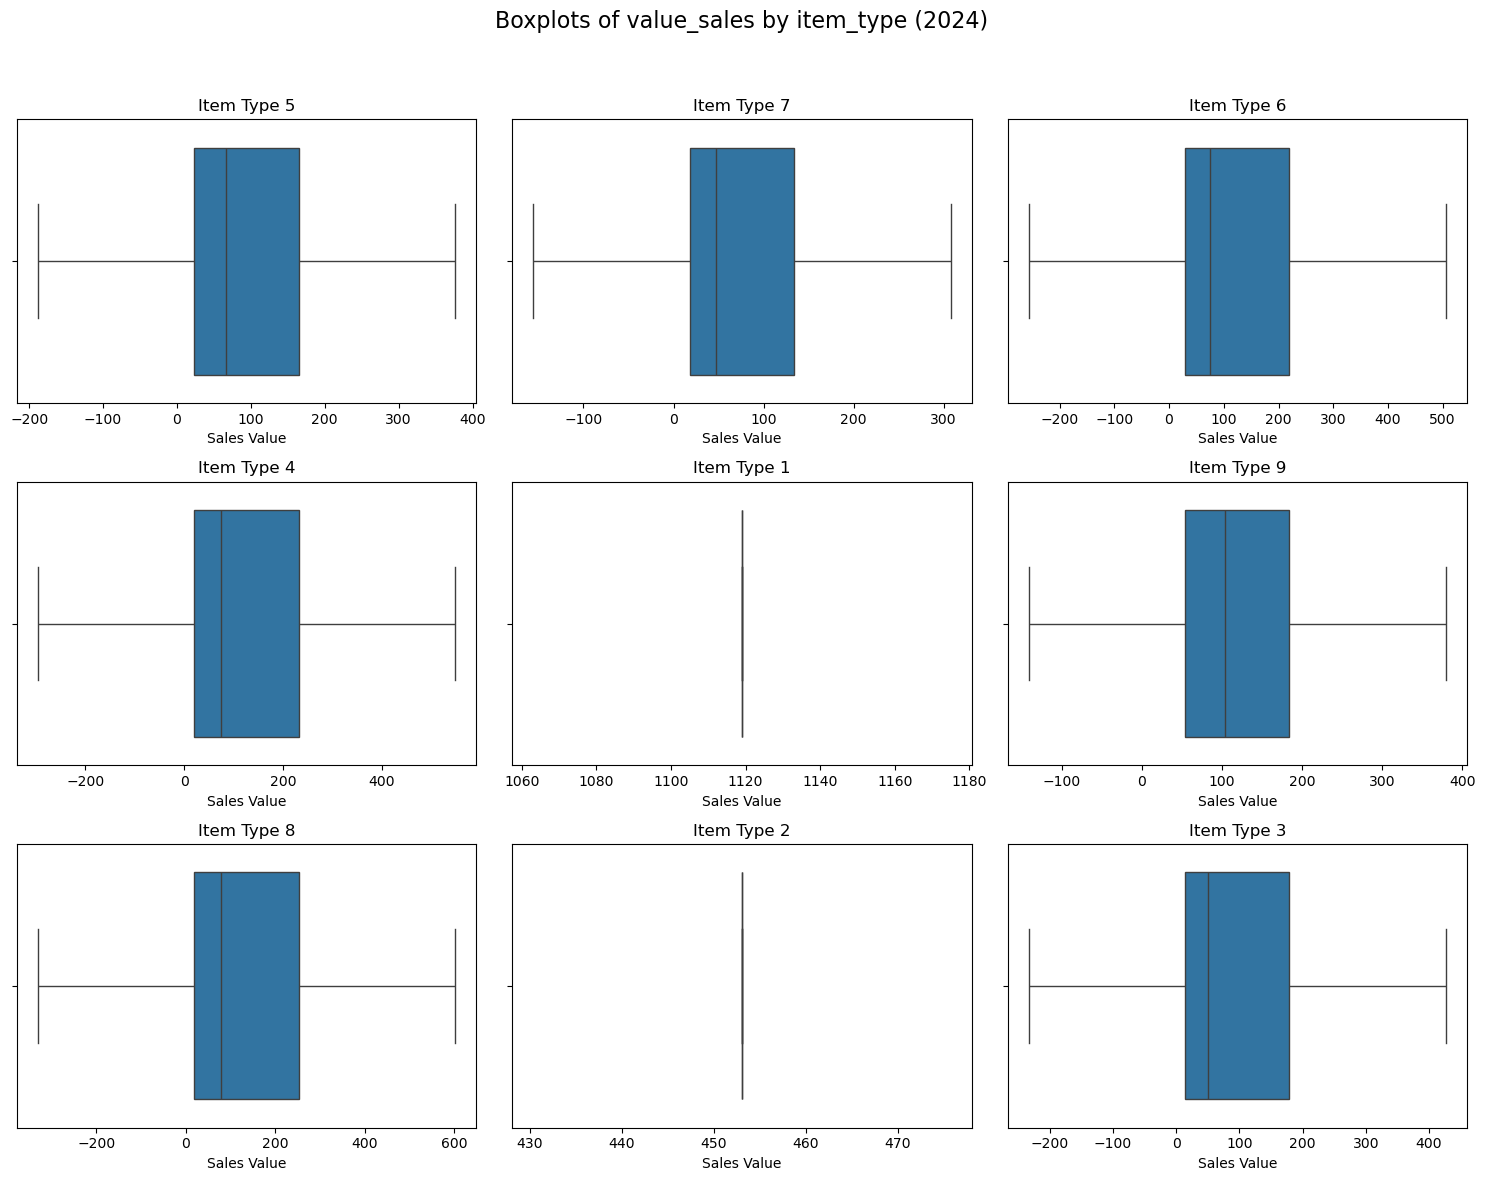

In [25]:
# Step 16: Function to clean item_type, cap outliers, fix skewness, and plot
def analyze_sales(df, year, cols=3):
    # Clean item_type 
    df = df[~df['item_type'].isna()]                       # Remove actual NaN
    df = df[~df['item_type'].str.upper().isin(['NAN','NA'])]  # Remove string NaN/NA
    df = df.reset_index(drop=True)
    
    # Ensure numeric
    df['value_sales'] = pd.to_numeric(df['value_sales'], errors='coerce')
    df['item_type'] = df['item_type'].astype('string')
    
    item_types = df['item_type'].unique()
    
    # Initial Outlier Summary 
    outlier_summary = []
    for item in item_types:
        group = df[df['item_type'] == item]
        q1 = group['value_sales'].quantile(0.25)
        q3 = group['value_sales'].quantile(0.75)
        iqr = q3 - q1
        lb = q1 - 1.5 * iqr
        ub = q3 + 1.5 * iqr
        
        lower_outliers = (group['value_sales'] < lb).sum()
        upper_outliers = (group['value_sales'] > ub).sum()
        total_outliers = lower_outliers + upper_outliers
        
        outlier_summary.append({
            'item_type': item,
            'lower_outliers': lower_outliers,
            'upper_outliers': upper_outliers,
            'total_outliers': total_outliers
        })
        
        # Cap outliers 
        df.loc[(df['item_type'] == item) & (df['value_sales'] < lb), 'value_sales'] = lb
        df.loc[(df['item_type'] == item) & (df['value_sales'] > ub), 'value_sales'] = ub
    
    outlier_df = pd.DataFrame(outlier_summary)
    print(f"\nYEAR {year}: Initial Outlier Summary ")
    display(outlier_df)
    
    # Fix extreme skewness
    skew_summary = []
    for item in item_types:
        group = df[df['item_type'] == item]
        skew_val = group['value_sales'].skew()
        skew_summary.append({'item_type': item, 'skewness': round(skew_val,3)})
        if abs(skew_val) > 1:
            mean_val = group['value_sales'].mean()
            df.loc[df['item_type'] == item, 'value_sales'] = mean_val
    
    skew_df = pd.DataFrame(skew_summary)
    print(f"\n YEAR {year}: Skewness Summary ")
    display(skew_df)
    
    # Boxplots 
    rows_box = math.ceil(len(item_types) / cols)
    plt.figure(figsize=(cols*5, rows_box*4))
    for i, item in enumerate(item_types, 1):
        group = df[df['item_type'] == item]
        plt.subplot(rows_box, cols, i)
        sns.boxplot(x=group['value_sales'])
        plt.title(f'Item Type {item}')
        plt.xlabel('Sales Value')
    plt.suptitle(f'Boxplots of value_sales by item_type ({year})', fontsize=16)
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()
    
    return df

# Apply to datasets and save back
df_2023 = analyze_sales(df_2023, 2023)
df_2024 = analyze_sales(df_2024, 2024)

YEAR 2023: Before Fixing Skewness 


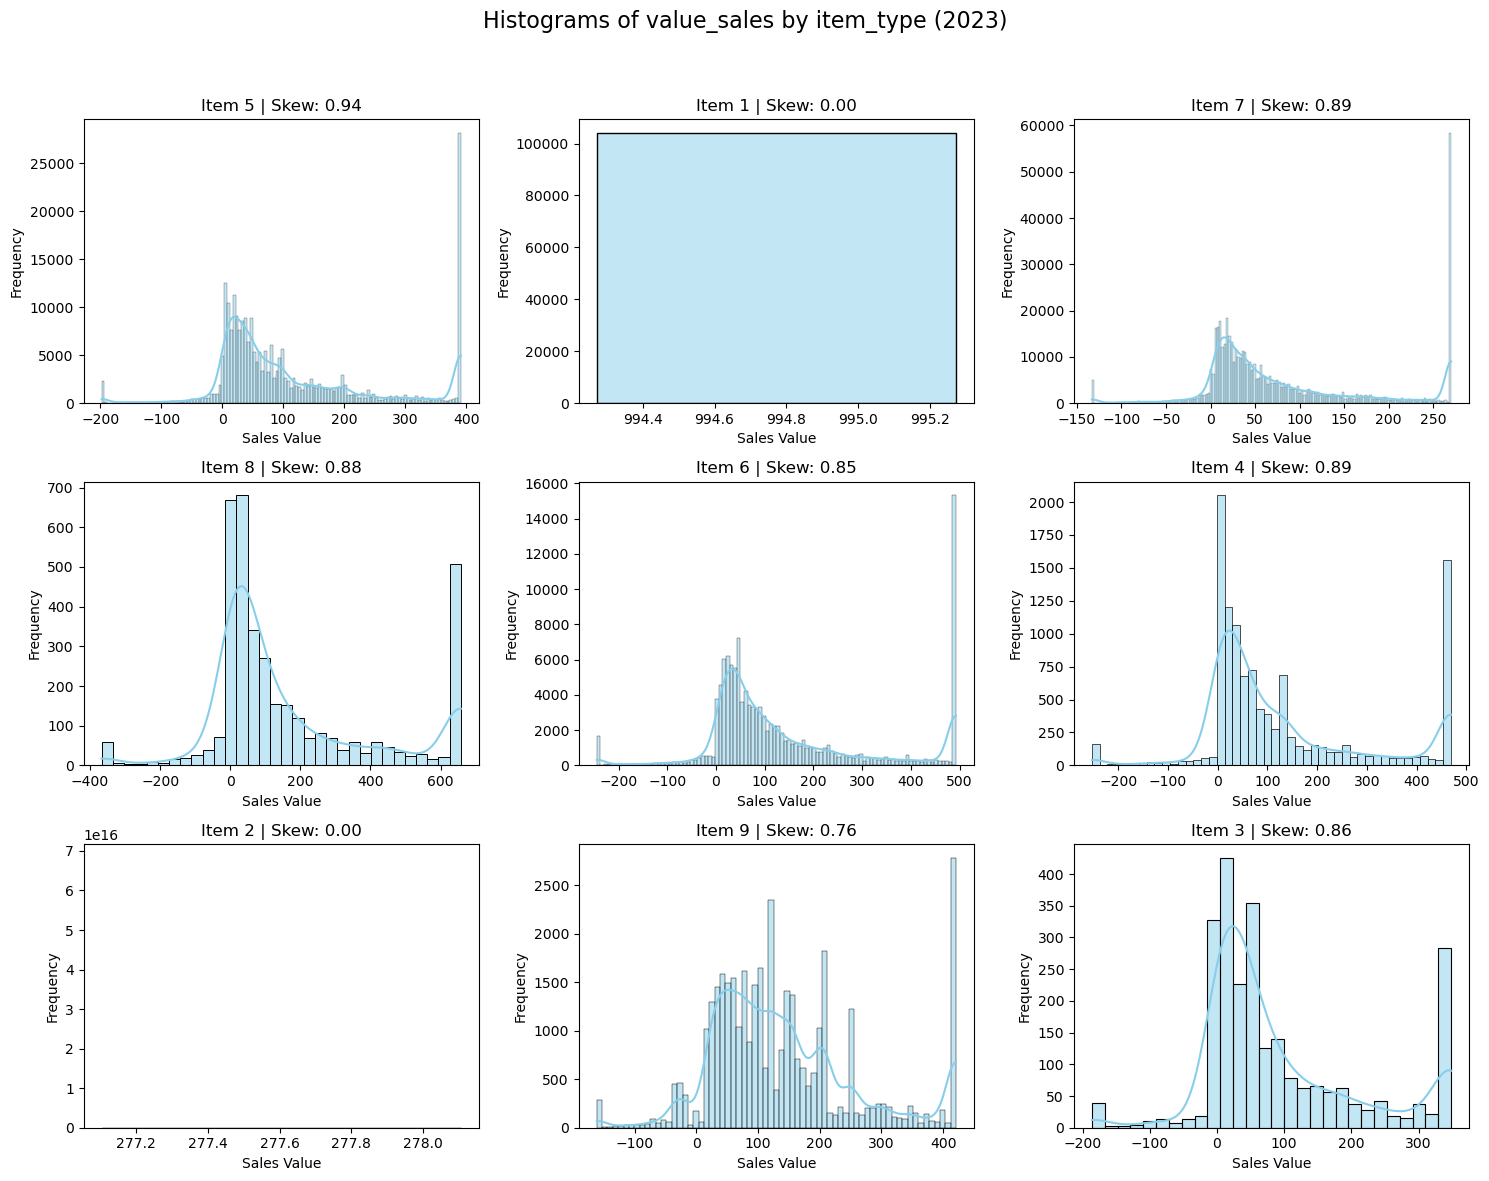

YEAR 2023: After Fixing Skewness 


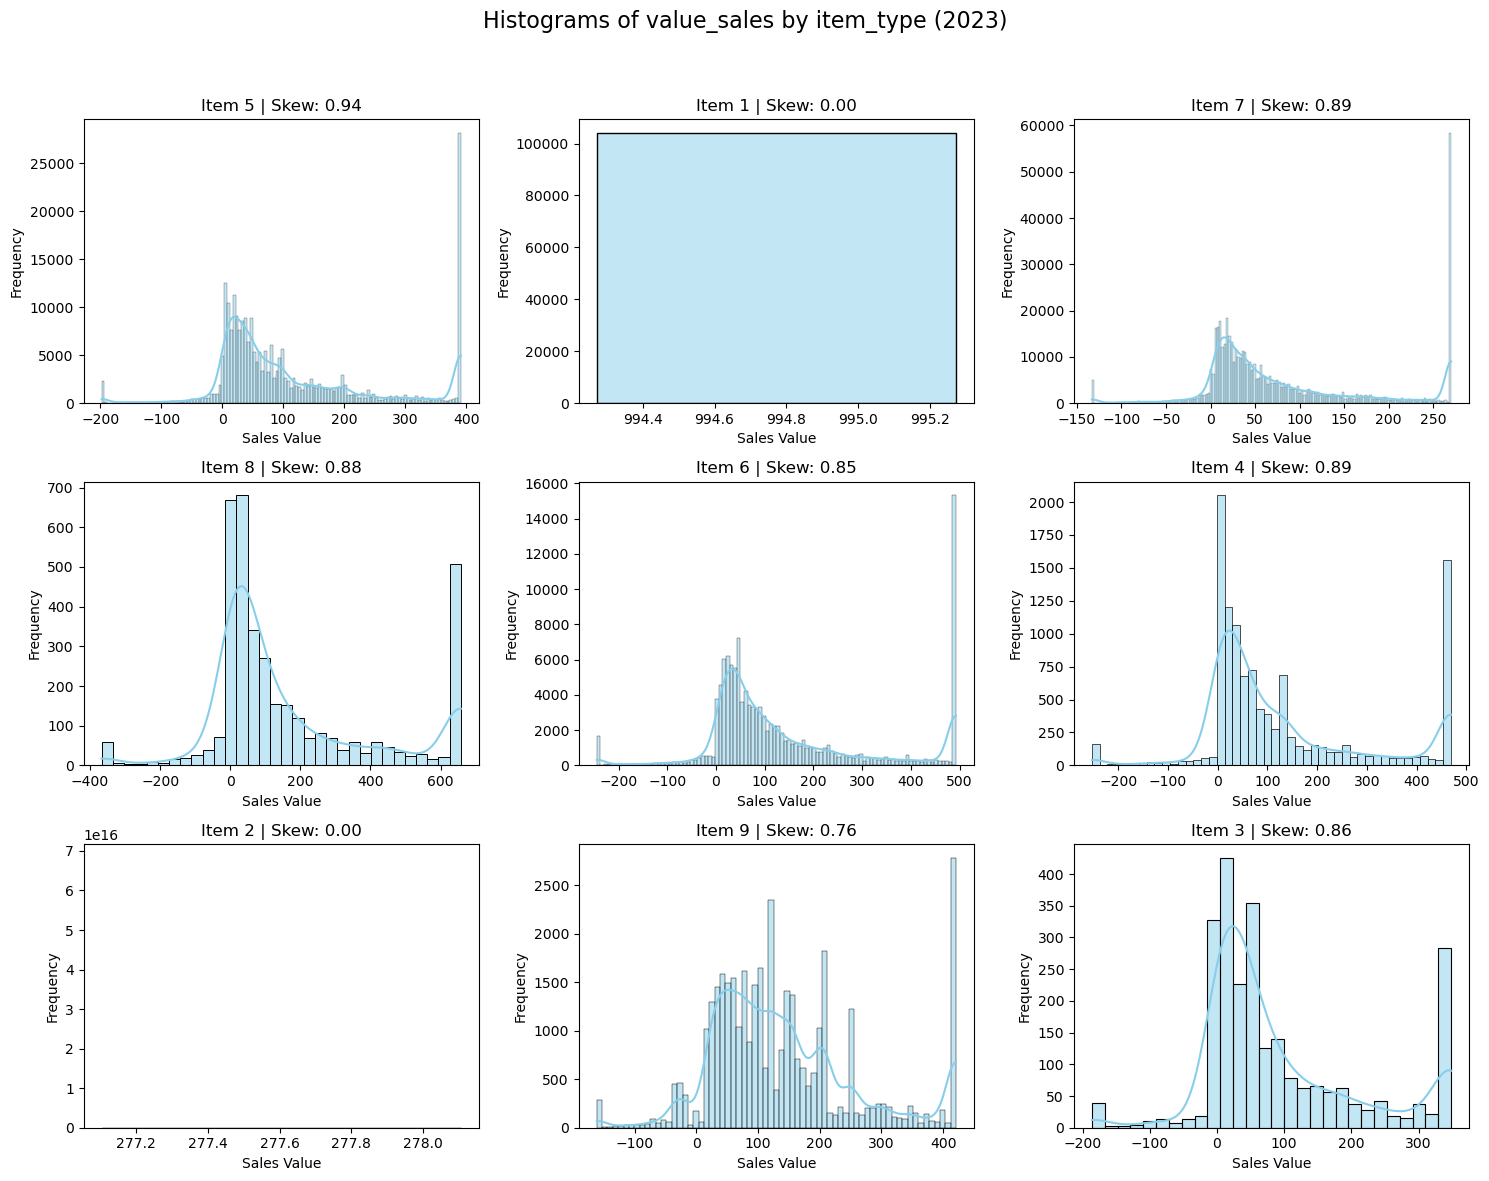

YEAR 2024: Before Fixing Skewness 


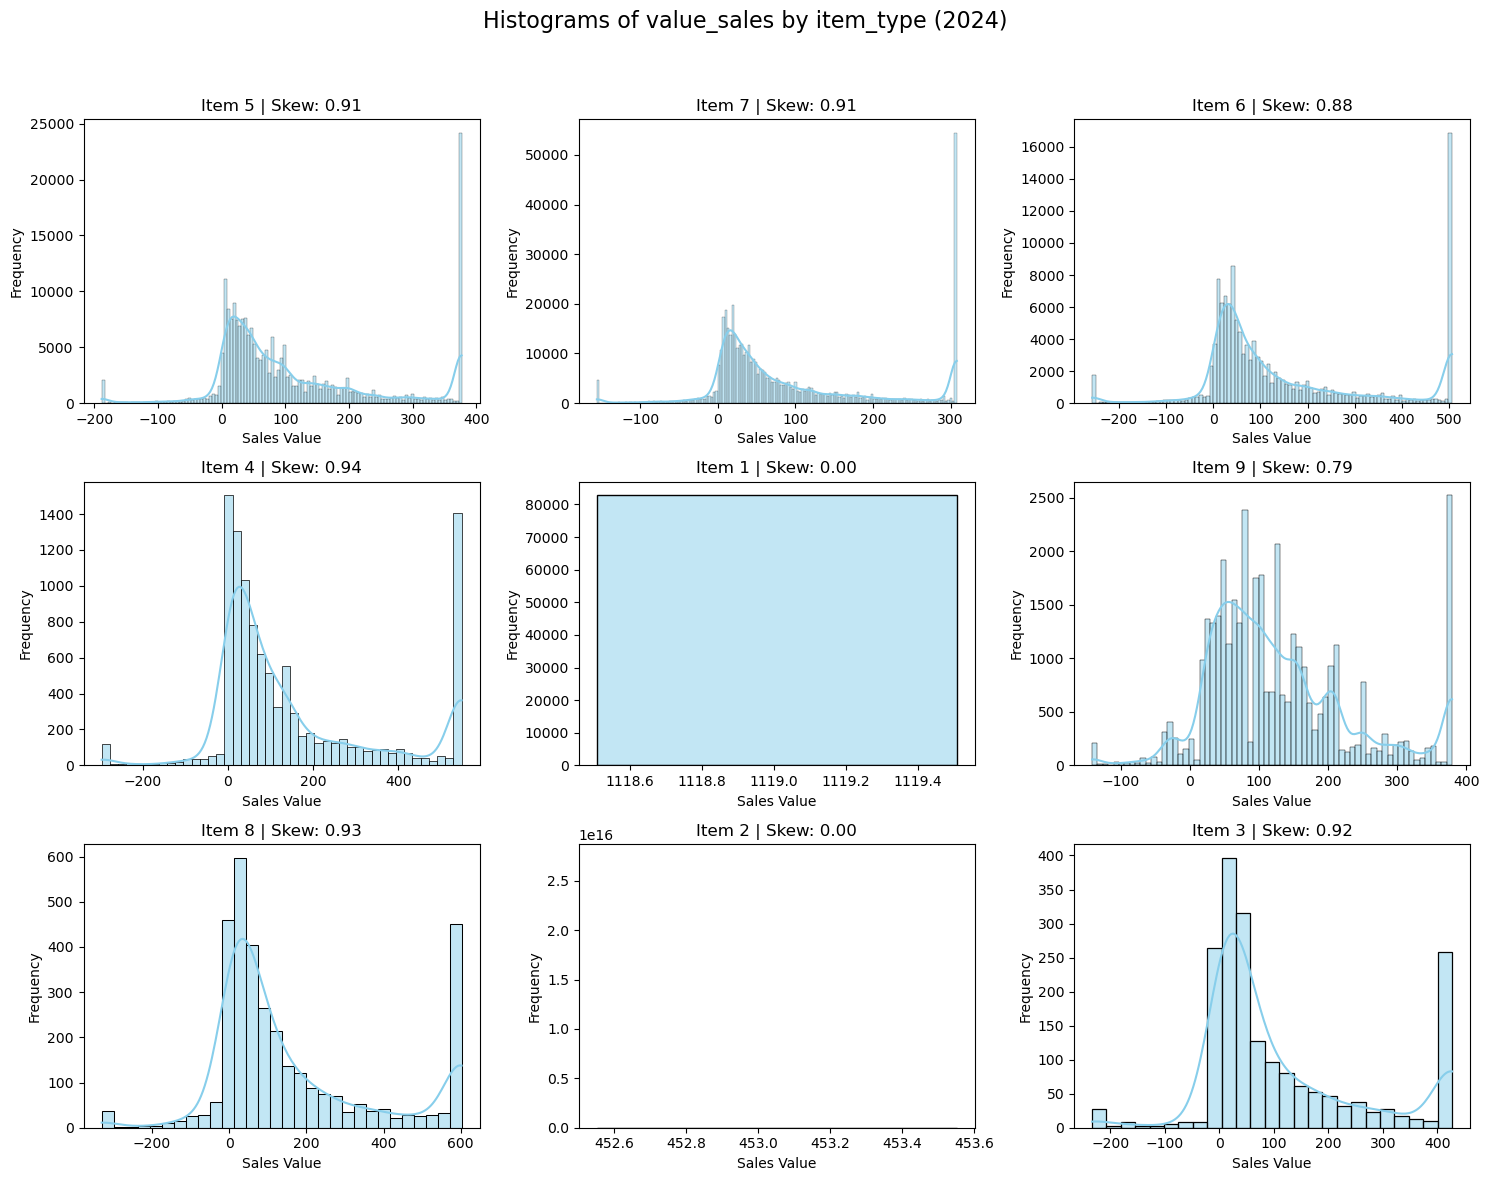

YEAR 2024: After Fixing Skewness 


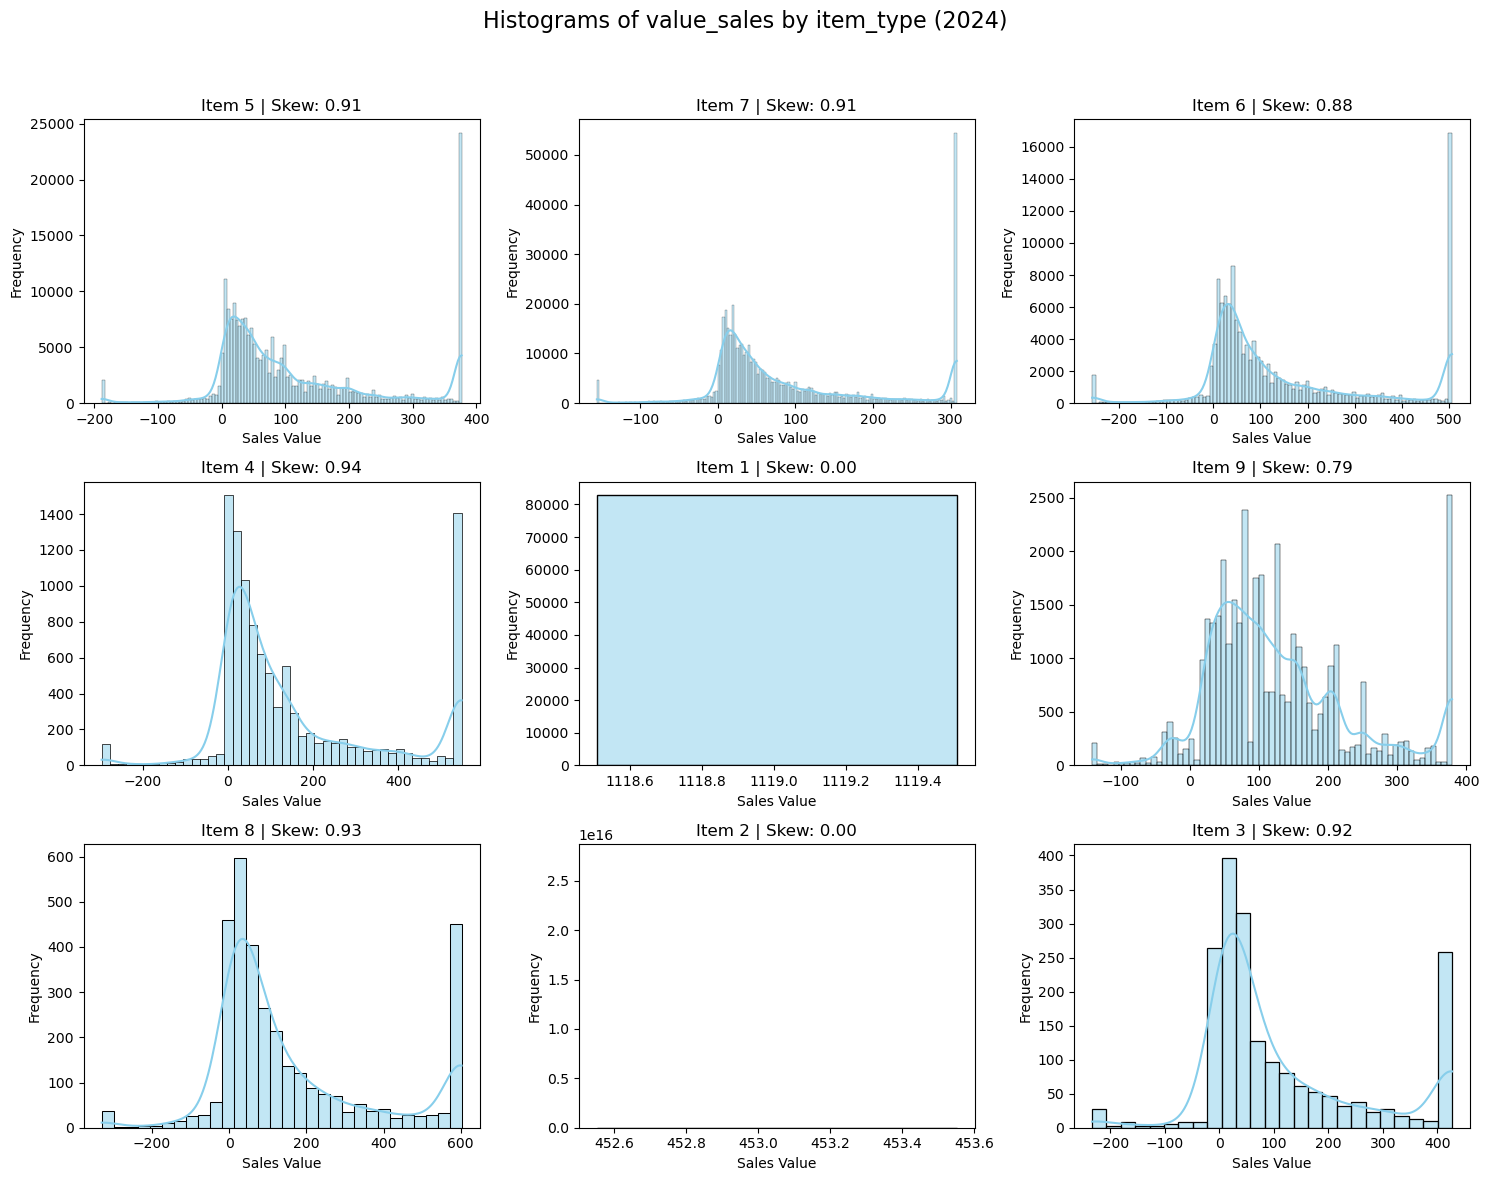

In [26]:
# Step 17: Function to visualize skewness
def plot_skew_hist(df, year, cols=3):
    item_types = df['item_type'].unique()
    rows = math.ceil(len(item_types) / cols)
    
    plt.figure(figsize=(cols*5, rows*4))
    
    for i, item in enumerate(item_types, 1):
        group = df[df['item_type'] == item]
        skew_val = group['value_sales'].skew()
        
        plt.subplot(rows, cols, i)
        sns.histplot(group['value_sales'], kde=True, color='skyblue')
        plt.title(f'Item {item} | Skew: {skew_val:.2f}')
        plt.xlabel('Sales Value')
        plt.ylabel('Frequency')
    
    plt.suptitle(f'Histograms of value_sales by item_type ({year})', fontsize=16)
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()

#  fix extreme skewness
def fix_skewness_with_mean(df):
    df_copy = df.copy()
    for item, group in df_copy.groupby("item_type"):
        skew_val = group["value_sales"].skew()
        if abs(skew_val) > 1:
            mean_val = group["value_sales"].mean()
            df_copy.loc[df_copy["item_type"] == item, "value_sales"] = mean_val
    return df_copy

# Apply to 2023 dataset
print("YEAR 2023: Before Fixing Skewness ")
plot_skew_hist(df_2023, 2023)
df_2023 = fix_skewness_with_mean(df_2023)
print("YEAR 2023: After Fixing Skewness ")
plot_skew_hist(df_2023, 2023)

#Apply to 2024 dataset
print("YEAR 2024: Before Fixing Skewness ")
plot_skew_hist(df_2024, 2024)
df_2024 = fix_skewness_with_mean(df_2024)
print("YEAR 2024: After Fixing Skewness ")
plot_skew_hist(df_2024, 2024)



In [27]:
#Final
# Save cleaned datasets to new CSV files
df_2023.to_csv('2023_cleaned_final.csv', index=False)
df_2024.to_csv('2024_cleaned_final.csv', index=False)

print("Cleaned 2023 dataset saved as '2023_cleaned_final.csv'")
print("Cleaned 2024 dataset saved as '2024_cleaned_final.csv'")

# Load them into new DataFrames
df_2023_new = pd.read_csv('2023_cleaned_final.csv', low_memory=False, )
df_2024_new = pd.read_csv('2024_cleaned_final.csv', low_memory=False, )

# Convert numeric columns back to appropriate types (for visualization)
numeric_cols = ['fiscal_year','fiscal_month','line_number','value_sales','value_cost','value_quantity','value_price_adjustment']
for df in [df_2023_new, df_2024_new]:
    for col in numeric_cols:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors='coerce')
    # Keep item_type as string
    df['item_type'] = df['item_type'].astype('string')

# Check
print(df_2023_new.dtypes)
print(df_2024_new.dtypes)
print(df_2023_new.shape)
print(df_2024_new.shape)


Cleaned 2023 dataset saved as '2023_cleaned_final.csv'
Cleaned 2024 dataset saved as '2024_cleaned_final.csv'
accounting_date                     object
fiscal_year                          int64
fiscal_month                         int64
company_code                         int64
customer_code                       object
customer_district_code               int64
item_code                           object
business_area_code                  object
item_group_code                     object
item_class_code                     object
item_type                   string[python]
bonus_group_code                    object
environment_group_code              object
technology_group_code               object
commission_group_code               object
reporting_classification            object
light_source                        object
warehouse_code                      object
abc_class_code                      object
abc_class_volume                    object
business_chain_l1_code        

# Answer Section 2: Exploratory Insights (all the codes in one cell - do not insert extra cells) 

## section 2.1 (Top 10 Salespersons by Sales Value Comparison (2023 vs 2024)) 

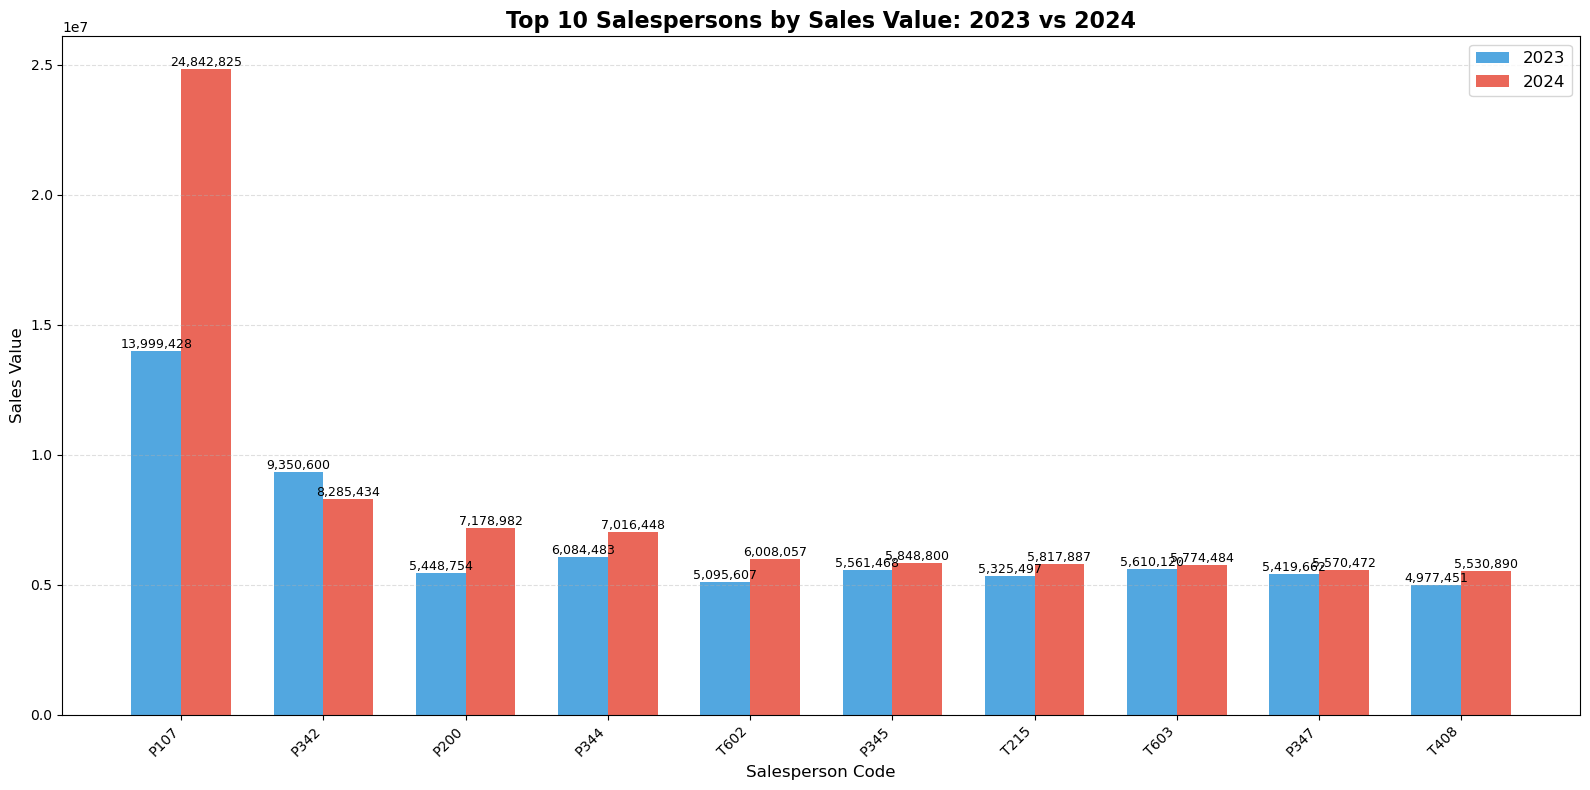

INSIGHT 2.1: Top 10 Salespersons Performance
Top 10 salespersons by value (2024):
P107: 24,842,825 (2024) vs 13,999,428 (2023) | Change: +77.5%
P342: 8,285,434 (2024) vs 9,350,600 (2023) | Change: -11.4%
P200: 7,178,982 (2024) vs 5,448,754 (2023) | Change: +31.8%
P344: 7,016,448 (2024) vs 6,084,483 (2023) | Change: +15.3%
T602: 6,008,057 (2024) vs 5,095,607 (2023) | Change: +17.9%
P345: 5,848,800 (2024) vs 5,561,468 (2023) | Change: +5.2%
T215: 5,817,887 (2024) vs 5,325,497 (2023) | Change: +9.2%
T603: 5,774,484 (2024) vs 5,610,120 (2023) | Change: +2.9%
P347: 5,570,472 (2024) vs 5,419,662 (2023) | Change: +2.8%
T408: 5,530,890 (2024) vs 4,977,451 (2023) | Change: +11.1%

Method: Grouped bar chart comparing top salespersons across two years
Insight: Reveals highest revenue-generating salespersons and year-over-year performance changes
Management Value: Supports sales performance evaluation, incentive planning, and resource allocation


In [28]:
# Section 2.1: Top 10 Salespersons by Sales Value Comparison (2023 vs 2024)

# Ensure value_sales is numeric
df_2023_new['value_sales'] = pd.to_numeric(df_2023_new['value_sales'], errors='coerce')
df_2024_new['value_sales'] = pd.to_numeric(df_2024_new['value_sales'], errors='coerce')

# Get top 10 salespersons in 2024 by total sales value
top10_sales_2024 = df_2024_new.groupby('salesperson_code')['value_sales'].sum().nlargest(10)

# Get corresponding sales in 2023
top_sales_list = top10_sales_2024.index.tolist()
sales_2023 = df_2023_new[df_2023_new['salesperson_code'].isin(top_sales_list)].groupby('salesperson_code')['value_sales'].sum()
sales_2024 = df_2024_new[df_2024_new['salesperson_code'].isin(top_sales_list)].groupby('salesperson_code')['value_sales'].sum()

# Align indices to ensure same order
sales_2023 = sales_2023.reindex(top_sales_list, fill_value=0)
sales_2024 = sales_2024.reindex(top_sales_list, fill_value=0)

# Plot grouped bar chart
import numpy as np
width = 0.35
x = np.arange(len(top_sales_list))

plt.figure(figsize=(16, 8))

# 2023 bars
plt.bar(x - width/2, sales_2023.values, width=width, label='2023', color='#3498db', alpha=0.85)
for x_pos, y in zip(x - width/2, sales_2023.values):
    plt.text(x_pos, y, f'{y:,.0f}', ha='center', va='bottom', fontsize=9)

# 2024 bars
plt.bar(x + width/2, sales_2024.values, width=width, label='2024', color='#e74c3c', alpha=0.85)
for x_pos, y in zip(x + width/2, sales_2024.values):
    plt.text(x_pos, y, f'{y:,.0f}', ha='center', va='bottom', fontsize=9)

# Chart formatting
plt.title('Top 10 Salespersons by Sales Value: 2023 vs 2024', fontsize=16, fontweight='bold')
plt.xlabel('Salesperson Code', fontsize=12)
plt.ylabel('Sales Value', fontsize=12)
plt.xticks(x, top_sales_list, rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.legend(fontsize=12)
plt.tight_layout()
plt.show()

# Print insights
print("INSIGHT 2.1: Top 10 Salespersons Performance")
print("Top 10 salespersons by value (2024):")
for sp, val_24 in sales_2024.items():
    val_23 = sales_2023.get(sp, 0)
    change = ((val_24 - val_23) / val_23 * 100) if val_23 > 0 else np.nan
    print(f"{sp}: {val_24:,.0f} (2024) vs {val_23:,.0f} (2023) | Change: {change:+.1f}%"
          if val_23>0 else f"{sp}: {val_24:,.0f} (2024) vs {val_23:,.0f} (2023) | Change: N/A")

print("\nMethod: Grouped bar chart comparing top salespersons across two years")
print("Insight: Reveals highest revenue-generating salespersons and year-over-year performance changes")
print("Management Value: Supports sales performance evaluation, incentive planning, and resource allocation")


## section 2.2 (Top 10 Business Chain by Sales Value Comparison (2023 vs 2024) 


=== Top 10 Business Chains by Value Sales (2023) ===
               business_chain_l1_name   value_sales
25      Metro Electrical Distributors  4.486690e+07
24                InterGlobal Trading  2.917040e+07
29       NextGen Electrical Solutions  1.884623e+07
3               BrightPower Solutions  1.674492e+07
27          Nationwide Lighting Group  1.470651e+07
13                    ElectraCorp Ltd  1.174084e+07
4             Builders Supply Network  1.124290e+07
1                 Aussie Energy Group  8.106620e+06
15              General Suppliers Pty  7.184545e+06
20  Independent Retailers Association  5.234858e+06

=== Top 10 Business Chains by Value Sales (2024) ===
               business_chain_l1_name   value_sales
29      Metro Electrical Distributors  4.206805e+07
28                InterGlobal Trading  2.848276e+07
32       NextGen Electrical Solutions  1.980754e+07
3               BrightPower Solutions  1.581364e+07
31          Nationwide Lighting Group  1.331801e+07
14      

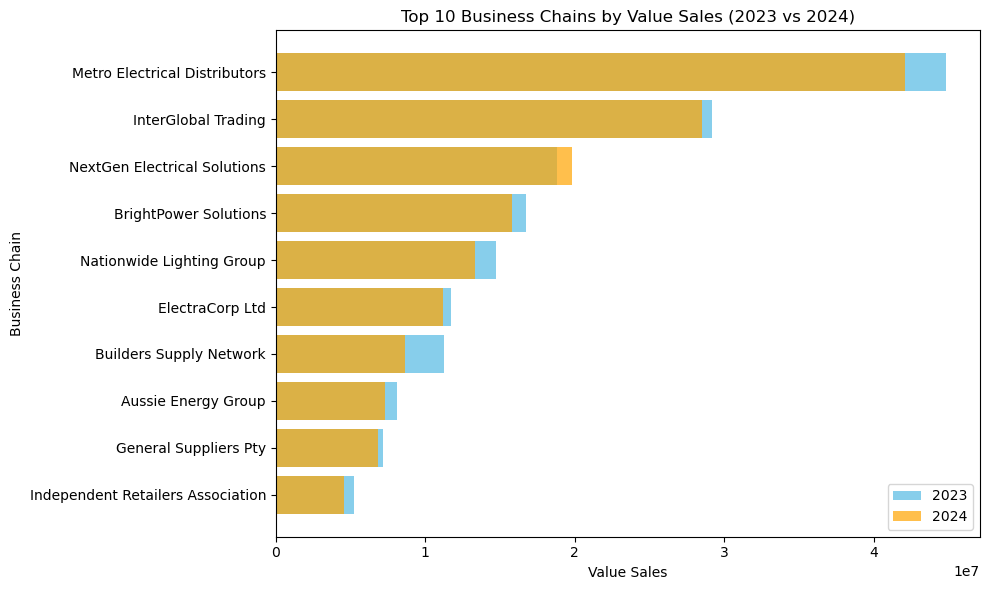


=== Insights ===
In 2023, **Metro Electrical Distributors** led all business chains with value sales of 44,866,903.
In 2024, **Metro Electrical Distributors** remained on top with value sales of 42,068,050.
Metro Electrical Distributors maintained its leadership position year-over-year.

Top 3 chains with the highest growth:
- NextGen Electrical Solutions: 5.1% increase
- InterGlobal Trading: -2.4% increase
- General Suppliers Pty: -4.7% increase

Top 3 chains with the steepest decline:
- Builders Supply Network: -23.2% decrease
- Independent Retailers Association: -12.8% decrease
- Aussie Energy Group: -9.9% decrease


In [29]:

import pandas as pd
import matplotlib.pyplot as plt

# Load cleaned datasets 
df_2023_new = pd.read_csv('2023_cleaned_final.csv', low_memory=False)
df_2024_new = pd.read_csv('2024_cleaned_final.csv', low_memory=False)

# Top 10 business chains by value sales (2023) 
top_10_2023 = (
    df_2023_new.groupby('business_chain_l1_name', as_index=False)['value_sales']
    .sum()
    .sort_values(by='value_sales', ascending=False)
    .head(10)
)

# Top 10 business chains by value sales (2024) 
top_10_2024 = (
    df_2024_new.groupby('business_chain_l1_name', as_index=False)['value_sales']
    .sum()
    .sort_values(by='value_sales', ascending=False)
    .head(10)
)

# Display results 
print("\n=== Top 10 Business Chains by Value Sales (2023) ===")
print(top_10_2023)
print("\n=== Top 10 Business Chains by Value Sales (2024) ===")
print(top_10_2024)

# Combine for comparison 
comparison = pd.merge(
    top_10_2023,
    top_10_2024,
    on='business_chain_l1_name',
    how='outer',
    suffixes=('_2023', '_2024')
).fillna(0)

comparison['change'] = comparison['value_sales_2024'] - comparison['value_sales_2023']
comparison['% change'] = (comparison['change'] / comparison['value_sales_2023'].replace(0, pd.NA)) * 100

print("\n=== Year-over-Year Comparison ===")
print(comparison.sort_values(by='value_sales_2024', ascending=False))

# Visualization 
plt.figure(figsize=(10,6))
plt.barh(top_10_2023['business_chain_l1_name'], top_10_2023['value_sales'], color='skyblue', label='2023')
plt.barh(top_10_2024['business_chain_l1_name'], top_10_2024['value_sales'], color='orange', alpha=0.7, label='2024')
plt.xlabel('Value Sales')
plt.ylabel('Business Chain')
plt.title('Top 10 Business Chains by Value Sales (2023 vs 2024)')
plt.legend()
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# Generate Insights 
print("\n=== Insights ===")
top_2023_name = top_10_2023.iloc[0]['business_chain_l1_name']
top_2024_name = top_10_2024.iloc[0]['business_chain_l1_name']
top_2023_value = top_10_2023.iloc[0]['value_sales']
top_2024_value = top_10_2024.iloc[0]['value_sales']

print(f"In 2023, **{top_2023_name}** led all business chains with value sales of {top_2023_value:,.0f}.")
print(f"In 2024, **{top_2024_name}** {'remained on top' if top_2024_name == top_2023_name else 'overtook others'} with value sales of {top_2024_value:,.0f}.")

if top_2024_name == top_2023_name:
    print(f"{top_2024_name} maintained its leadership position year-over-year.")
else:
    print(f"Leadership changed from **{top_2023_name}** in 2023 to **{top_2024_name}** in 2024.")

# Top gainers and losers
gainers = comparison.sort_values(by='% change', ascending=False).head(3)
losers = comparison.sort_values(by='% change', ascending=True).head(3)

print("\nTop 3 chains with the highest growth:")
for _, row in gainers.iterrows():
    print(f"- {row['business_chain_l1_name']}: {row['% change']:.1f}% increase")

print("\nTop 3 chains with the steepest decline:")
for _, row in losers.iterrows():
    print(f"- {row['business_chain_l1_name']}: {row['% change']:.1f}% decrease")


## section 2.3 (Light Source Contribution to Total Sales (2023 vs 2024)) 


Light Source Contribution to Total Sales (2023)
  light_source   value_sales  percentage
2  Traditional  1.397444e+08   70.719603
0  Accessories  4.578786e+07   23.171584
1          LED  1.207123e+07    6.108814

Light Source Contribution to Total Sales (2024) 
  light_source   value_sales  percentage
2  Traditional  1.244867e+08   67.115043
0  Accessories  3.777274e+07   20.364583
1          LED  2.322310e+07   12.520374


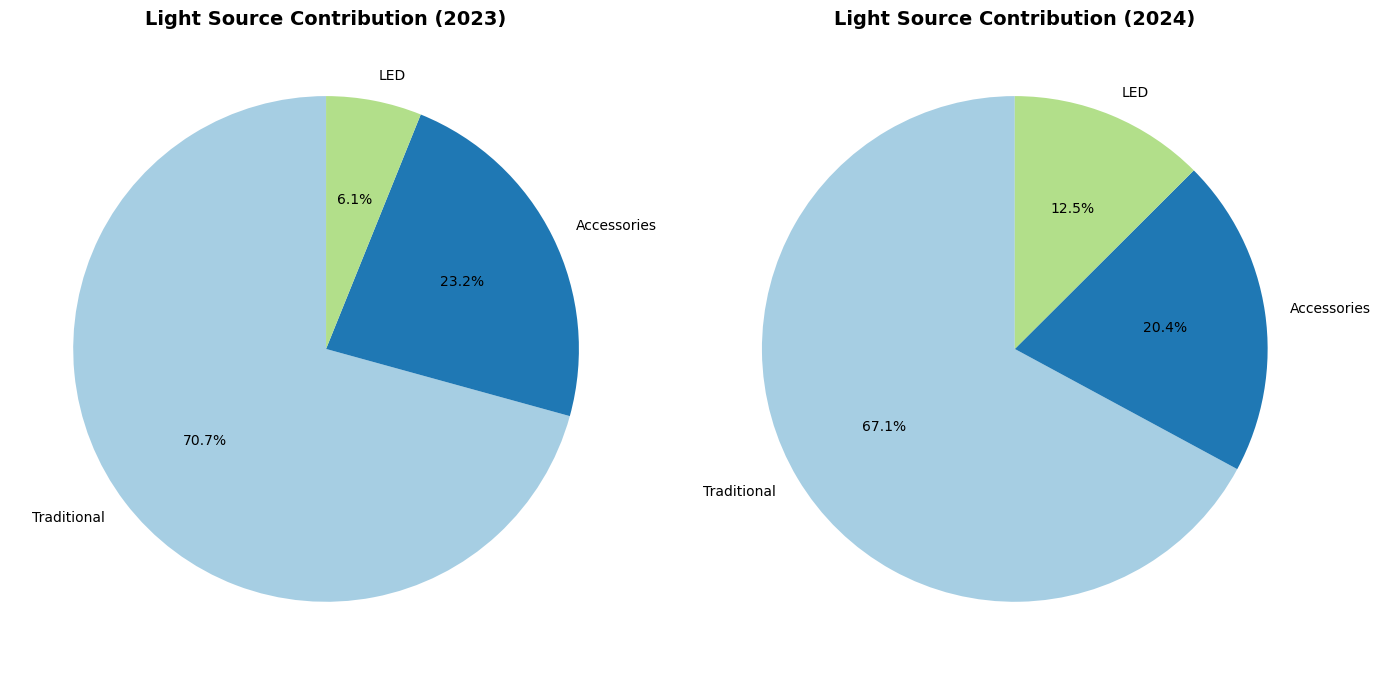


Insights 
In 2023, **Traditional** contributed the highest share, accounting for 70.7% of total sales.
In 2024, **Traditional** remained dominant, representing 67.1% of total sales.
The same light source continued to lead in both years.

 Top 3 light sources with the highest growth in sales value:
- LED: 92.4% increase
- Traditional: -10.9% increase
- Accessories: -17.5% increase

 Top 3 light sources with the steepest decline in sales value:
- Accessories: -17.5% decrease
- Traditional: -10.9% decrease
- LED: 92.4% decrease

 **Insight 2.3: Light Source Contribution Analysis**
The pie charts visualize how each lighting type contributed to total sales in both years.
**Management Value:** This helps identify dominant and emerging lighting technologies, supporting decisions in product focus, marketing strategy, and production allocation.


In [30]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Load cleaned datasets 
df_2023_new = pd.read_csv('2023_cleaned_final.csv', low_memory=False)
df_2024_new = pd.read_csv('2024_cleaned_final.csv', low_memory=False)

# Clean: Replace 'NAN' strings with actual NaN, then drop missing values 
df_2023_new['light_source'] = df_2023_new['light_source'].replace('NAN', np.nan)
df_2024_new['light_source'] = df_2024_new['light_source'].replace('NAN', np.nan)

df_2023_new = df_2023_new.dropna(subset=['light_source'])
df_2024_new = df_2024_new.dropna(subset=['light_source'])

# Group by light_source and calculate total sales value
sales_2023 = (
    df_2023_new.groupby('light_source', as_index=False)['value_sales']
    .sum()
    .sort_values(by='value_sales', ascending=False)
)
sales_2024 = (
    df_2024_new.groupby('light_source', as_index=False)['value_sales']
    .sum()
    .sort_values(by='value_sales', ascending=False)
)

# Calculate percentage contribution 
sales_2023['percentage'] = (sales_2023['value_sales'] / sales_2023['value_sales'].sum()) * 100
sales_2024['percentage'] = (sales_2024['value_sales'] / sales_2024['value_sales'].sum()) * 100

# Display data 
print("\nLight Source Contribution to Total Sales (2023)")
print(sales_2023)
print("\nLight Source Contribution to Total Sales (2024) ")
print(sales_2024)

# --- Visualization: Side-by-side Pie Charts ---
fig, axes = plt.subplots(1, 2, figsize=(14, 7))

# 2023 Pie Chart
axes[0].pie(
    sales_2023['value_sales'],
    labels=sales_2023['light_source'],
    autopct='%1.1f%%',
    startangle=90,
    colors=plt.cm.Paired.colors,
    textprops={'fontsize': 10}
)
axes[0].set_title('Light Source Contribution (2023)', fontsize=14, fontweight='bold')

# 2024 Pie Chart
axes[1].pie(
    sales_2024['value_sales'],
    labels=sales_2024['light_source'],
    autopct='%1.1f%%',
    startangle=90,
    colors=plt.cm.Paired.colors,
    textprops={'fontsize': 10}
)
axes[1].set_title('Light Source Contribution (2024)', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

# Insights 
print("\nInsights ")

top_2023 = sales_2023.iloc[0]
top_2024 = sales_2024.iloc[0]

print(f"In 2023, **{top_2023['light_source']}** contributed the highest share, accounting for {top_2023['percentage']:.1f}% of total sales.")
print(f"In 2024, **{top_2024['light_source']}** {'remained dominant' if top_2024['light_source'] == top_2023['light_source'] else 'took the lead'}, representing {top_2024['percentage']:.1f}% of total sales.")

if top_2023['light_source'] == top_2024['light_source']:
    print("The same light source continued to lead in both years.")
else:
    print(f" Leadership shifted from **{top_2023['light_source']}** in 2023 to **{top_2024['light_source']}** in 2024.")

# Year-over-year comparison 
comparison = pd.merge(
    sales_2023[['light_source', 'value_sales', 'percentage']],
    sales_2024[['light_source', 'value_sales', 'percentage']],
    on='light_source',
    how='outer',
    suffixes=('_2023', '_2024')
).fillna(0)

comparison['% change (value)'] = (
    (comparison['value_sales_2024'] - comparison['value_sales_2023'])
    / comparison['value_sales_2023'].replace(0, pd.NA)
) * 100

# Top growth and decline 
gainers = comparison.sort_values(by='% change (value)', ascending=False).head(3)
losers = comparison.sort_values(by='% change (value)', ascending=True).head(3)

print("\n Top 3 light sources with the highest growth in sales value:")
for _, row in gainers.iterrows():
    print(f"- {row['light_source']}: {row['% change (value)']:.1f}% increase")

print("\n Top 3 light sources with the steepest decline in sales value:")
for _, row in losers.iterrows():
    print(f"- {row['light_source']}: {row['% change (value)']:.1f}% decrease")

print("\n **Insight 2.3: Light Source Contribution Analysis**")
print("The pie charts visualize how each lighting type contributed to total sales in both years.")
print("**Management Value:** This helps identify dominant and emerging lighting technologies, supporting decisions in product focus, marketing strategy, and production allocation.")


## section 2.4 (Sales Quantity of Each Item Type: 2023 vs 2024) 

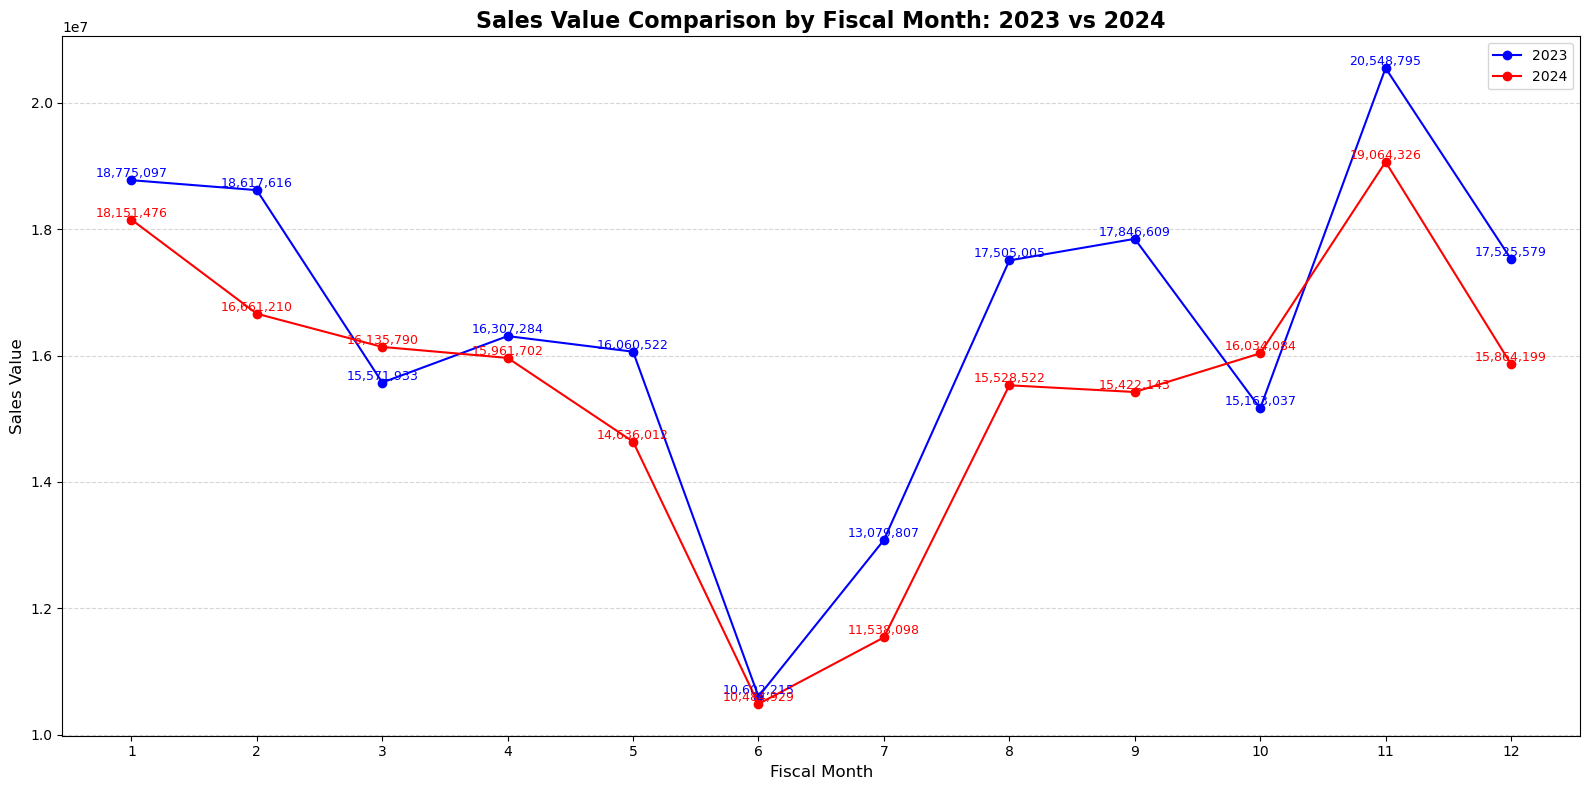


Insights: Fiscal Month Sales Analysis 
In 2023, Fiscal Month **11** recorded the highest sales value at 20,548,795.
In 2024, Fiscal Month **11** remained dominant, with sales of 19,064,326.
The same fiscal month led in both years, showing consistent seasonal strength.

Top 3 Fiscal Months with Highest Growth in Sales Value:
- Month 10: 5.7% increase (15,163,037 → 16,034,084)
- Month 3: 3.6% increase (15,571,933 → 16,135,790)
- Month 6: -1.1% increase (10,602,215 → 10,484,929)

Top 3 Fiscal Months with Largest Decline in Sales Value:
- Month 9: -13.6% decrease (17,846,609 → 15,422,143)
- Month 7: -11.8% decrease (13,079,807 → 11,538,098)
- Month 8: -11.3% decrease (17,505,005 → 15,528,522)

**Insight Summary:**
This comparison highlights how sales performance fluctuated month-to-month between 2023 and 2024.
- Consistent peak months suggest strong seasonal demand patterns.
- Shifts in top-performing months may indicate timing changes in campaigns, product launches, or consumer behavior.

In [31]:

# Load cleaned datasets 
df_2023_cleaned = pd.read_csv('2023_cleaned_final.csv', low_memory=False)
df_2024_cleaned = pd.read_csv('2024_cleaned_final.csv', low_memory=False)

# Group sales value by fiscal month 
sales2023 = df_2023_cleaned.groupby('fiscal_month')['value_sales'].sum().sort_index()
sales2024 = df_2024_cleaned.groupby('fiscal_month')['value_sales'].sum().sort_index()

# Plotting line graph 
plt.figure(figsize=(16, 8))

# 2023 line
plt.plot(sales2023.index, sales2023.values, marker='o', linestyle='-', color='blue', label='2023')
for x, y in zip(sales2023.index, sales2023.values):
    plt.text(x, y, f'{y:,.0f}', ha='center', va='bottom', fontsize=9, color='blue')

# 2024 line
plt.plot(sales2024.index, sales2024.values, marker='o', linestyle='-', color='red', label='2024')
for x, y in zip(sales2024.index, sales2024.values):
    plt.text(x, y, f'{y:,.0f}', ha='center', va='bottom', fontsize=9, color='red')

# Formatting 
plt.title('Sales Value Comparison by Fiscal Month: 2023 vs 2024', fontsize=16, fontweight='bold')
plt.xlabel('Fiscal Month', fontsize=12)
plt.ylabel('Sales Value', fontsize=12)
plt.xticks(range(1, 13))
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()
#Insights
print("\nInsights: Fiscal Month Sales Analysis ")

# Combine 2023 and 2024 data for comparison
comparison = pd.merge(
    sales2023.rename('value_sales_2023'),
    sales2024.rename('value_sales_2024'),
    left_index=True, right_index=True,
    how='outer'
).fillna(0)

# Calculate percentage change
comparison['% change (value_sales)'] = (
    (comparison['value_sales_2024'] - comparison['value_sales_2023'])
    / comparison['value_sales_2023'].replace(0, pd.NA)
) * 100

# Identify top fiscal months
top_2023 = comparison['value_sales_2023'].idxmax()
top_2024 = comparison['value_sales_2024'].idxmax()

print(f"In 2023, Fiscal Month **{top_2023}** recorded the highest sales value "
      f"at {comparison.loc[top_2023, 'value_sales_2023']:,.0f}.")

print(f"In 2024, Fiscal Month **{top_2024}** "
      f"{'remained dominant' if top_2024 == top_2023 else 'took the lead'}, "
      f"with sales of {comparison.loc[top_2024, 'value_sales_2024']:,.0f}.")

if top_2024 == top_2023:
    print("The same fiscal month led in both years, showing consistent seasonal strength.")
else:
    print(f"Leadership shifted from Fiscal Month {top_2023} in 2023 "
          f"to Fiscal Month {top_2024} in 2024, suggesting a change in sales peak timing.")

# Top 3 growth and decline months 
gainers = comparison.sort_values(by='% change (value_sales)', ascending=False).head(3)
decliners = comparison.sort_values(by='% change (value_sales)', ascending=True).head(3)

print("\nTop 3 Fiscal Months with Highest Growth in Sales Value:")
for idx, row in gainers.iterrows():
    print(f"- Month {idx}: {row['% change (value_sales)']:.1f}% increase "
          f"({row['value_sales_2023']:,.0f} → {row['value_sales_2024']:,.0f})")

print("\nTop 3 Fiscal Months with Largest Decline in Sales Value:")
for idx, row in decliners.iterrows():
    print(f"- Month {idx}: {row['% change (value_sales)']:.1f}% decrease "
          f"({row['value_sales_2023']:,.0f} → {row['value_sales_2024']:,.0f})")

# Summary insight
print("\n**Insight Summary:**")
print("This comparison highlights how sales performance fluctuated month-to-month between 2023 and 2024.")
print("- Consistent peak months suggest strong seasonal demand patterns.")
print("- Shifts in top-performing months may indicate timing changes in campaigns, product launches, or consumer behavior.")
print("- Growth and decline insights can guide future planning for inventory, marketing, and production scheduling.")



2.4 Sales value trends and comparison in 2023 and 2024 are visualised by using a line plot. A line plot is chosen since it clearly shows the changes in sales value throughout the year and allows direct comparison of the two years in one graph. In this visualisation, the data of sales value is grouped by fiscal month, then the trends in 2023 and 2024 are shown by lines with different colors and labels.<br>In 2023, the highest value of sales was observed in December, reaching approximately 20,548,795, while the lowest occurred in June, around 10,602,215. In 2024, December recorded the highest value of sales at roughly 19,063,835, whereas June marked the lowest, approximately 10,484,703. A comparative analysis across the two years reveals a consistent seasonal pattern: sales generally decline from January through July and reach the lowest point, then increase from July to December and reach the peak. This indicates that the mid-year period consistently experiences lower sales performance and December has the best sales performance over the entire sales cycle.<br>This insight can help management identify the seasonal or cyclical patterns in business to optimize resource allocation. Management can also evaluate annual performance through comparisons and adjust marketing activity plans for the following year to maximize the overall profit.

## section 2.5 (Sales Quantity of Each Item in 2023 and 2024)

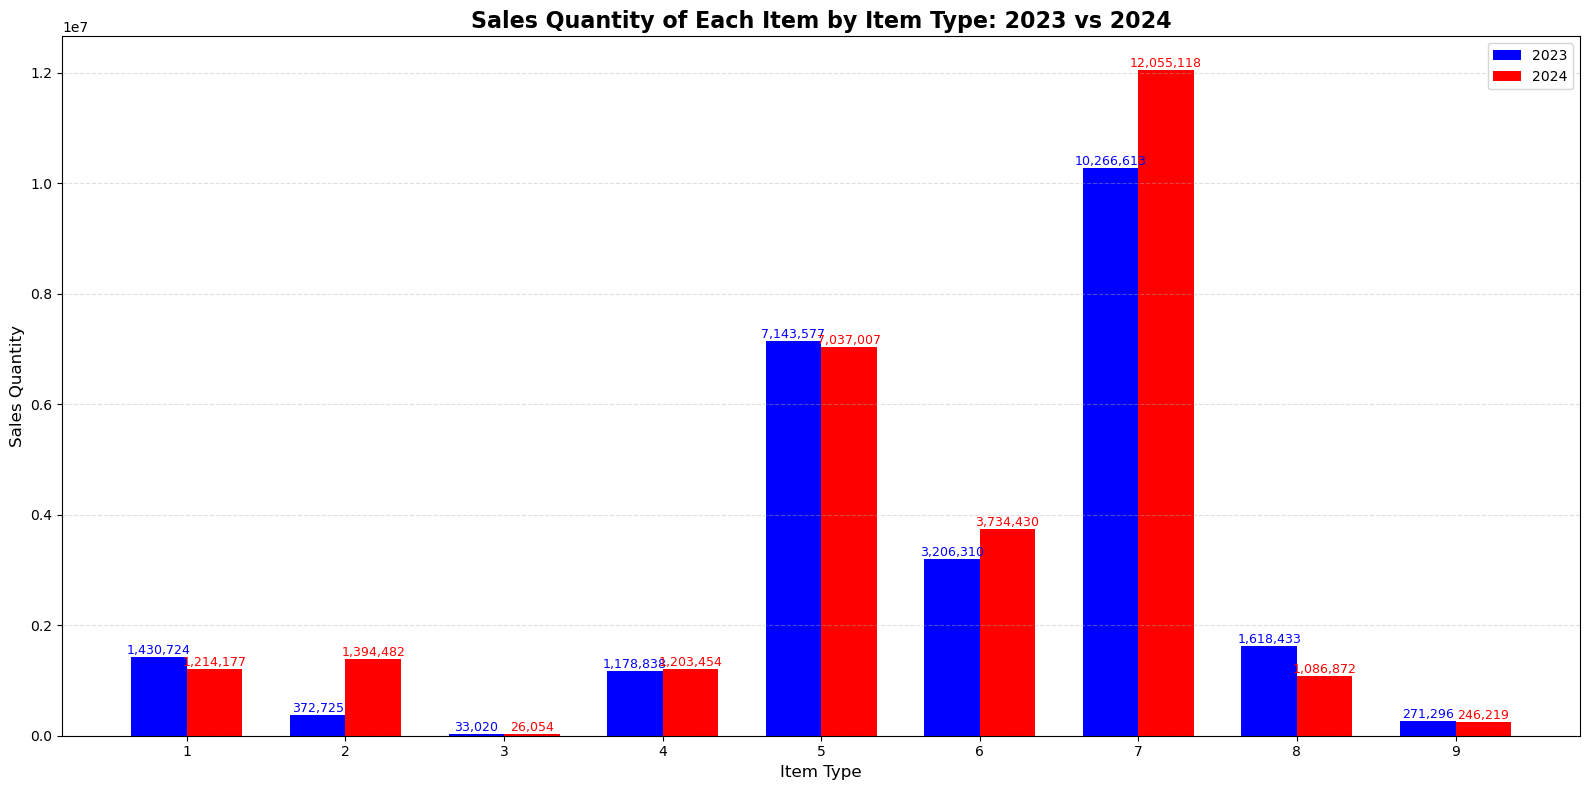


=== Insights: Item Type Sales Quantity Analysis ===
In 2023, Item Type **7** recorded the highest sales quantity with 10,266,613 units sold.
In 2024, Item Type **7** remained dominant, with 12,055,118 units sold.
The same item type continued to lead in both years, showing consistent product demand.

 Top 3 Item Types with the Highest Growth in Sales Quantity:
- Item Type 2: 274.1% increase (372,725 → 1,394,482)
- Item Type 7: 17.4% increase (10,266,613 → 12,055,118)
- Item Type 6: 16.5% increase (3,206,310 → 3,734,430)

Top 3 Item Types with the Largest Decline in Sales Quantity:
- Item Type 8: -32.8% decrease (1,618,433 → 1,086,872)
- Item Type 3: -21.1% decrease (33,020 → 26,054)
- Item Type 1: -15.1% decrease (1,430,724 → 1,214,177)

**Insight Summary:**
This comparison shows which item types gained or lost popularity between 2023 and 2024.
- Consistent top item types reflect stable demand and customer loyalty.
- Growth leaders highlight potential focus areas for marketing or inven

In [32]:
 
# Load cleaned datasets 
df_2023_new = pd.read_csv('2023_cleaned_final.csv', low_memory=False)
df_2024_new = pd.read_csv('2024_cleaned_final.csv', low_memory=False)

# Remove UNKNOWN or NaN item_type rows 
df_2023_new = df_2023_new[df_2023_new['item_type'].notna() & (df_2023_new['item_type'] != 'UNKNOWN')]
df_2024_new = df_2024_new[df_2024_new['item_type'].notna() & (df_2024_new['item_type'] != 'UNKNOWN')]

# Convert item_type to integer 
df_2023_new['item_type'] = df_2023_new['item_type'].astype(int)
df_2024_new['item_type'] = df_2024_new['item_type'].astype(int)

# Group and sum total sales quantity per item_type 
quantity2023 = df_2023_new.groupby('item_type')['value_quantity'].sum().sort_index()
quantity2024 = df_2024_new.groupby('item_type')['value_quantity'].sum().sort_index()

# Define bar width 
width = 0.35

# Create bar chart 
plt.figure(figsize=(16, 8))

# 2023 bars
plt.bar([x - width/2 for x in quantity2023.index], quantity2023.values,
        width=width, color='blue', label='2023')
for x, y in zip(quantity2023.index, quantity2023.values):
    plt.text(x - width/2, y, f'{y:,.0f}', ha='center', va='bottom', fontsize=9, color='blue')

# 2024 bars
plt.bar([x + width/2 for x in quantity2024.index], quantity2024.values,
        width=width, color='red', label='2024')
for x, y in zip(quantity2024.index, quantity2024.values):
    plt.text(x + width/2, y, f'{y:,.0f}', ha='center', va='bottom', fontsize=9, color='red')

# --- Formatting ---
plt.title('Sales Quantity of Each Item by Item Type: 2023 vs 2024', fontsize=16, fontweight='bold')
plt.xlabel('Item Type', fontsize=12)
plt.ylabel('Sales Quantity', fontsize=12)
plt.xticks(sorted(set(quantity2023.index) | set(quantity2024.index)))
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.legend()
plt.tight_layout()
plt.show()
# Insights 
print("\n=== Insights: Item Type Sales Quantity Analysis ===")

# Combine both years for comparison 
comparison = pd.merge(
    quantity2023.rename('quantity_2023'),
    quantity2024.rename('quantity_2024'),
    left_index=True, right_index=True,
    how='outer'
).fillna(0)

# Calculate percentage change 
comparison['% change (quantity)'] = (
    (comparison['quantity_2024'] - comparison['quantity_2023'])
    / comparison['quantity_2023'].replace(0, pd.NA)
) * 100

# Identify top item types 
top_2023 = comparison['quantity_2023'].idxmax()
top_2024 = comparison['quantity_2024'].idxmax()

print(f"In 2023, Item Type **{top_2023}** recorded the highest sales quantity "
      f"with {comparison.loc[top_2023, 'quantity_2023']:,.0f} units sold.")

print(f"In 2024, Item Type **{top_2024}** "
      f"{'remained dominant' if top_2024 == top_2023 else 'took the lead'}, "
      f"with {comparison.loc[top_2024, 'quantity_2024']:,.0f} units sold.")

if top_2024 == top_2023:
    print("The same item type continued to lead in both years, showing consistent product demand.")
else:
    print(f"Leadership shifted from Item Type {top_2023} in 2023 "
          f"to Item Type {top_2024} in 2024, suggesting changes in consumer preference or product focus.")

# Top 3 growth and decline item types 
gainers = comparison.sort_values(by='% change (quantity)', ascending=False).head(3)
decliners = comparison.sort_values(by='% change (quantity)', ascending=True).head(3)

print("\n Top 3 Item Types with the Highest Growth in Sales Quantity:")
for idx, row in gainers.iterrows():
    print(f"- Item Type {idx}: {row['% change (quantity)']:.1f}% increase "
          f"({row['quantity_2023']:,.0f} → {row['quantity_2024']:,.0f})")

print("\nTop 3 Item Types with the Largest Decline in Sales Quantity:")
for idx, row in decliners.iterrows():
    print(f"- Item Type {idx}: {row['% change (quantity)']:.1f}% decrease "
          f"({row['quantity_2023']:,.0f} → {row['quantity_2024']:,.0f})")

# Summary Insight 
print("\n**Insight Summary:**")
print("This comparison shows which item types gained or lost popularity between 2023 and 2024.")
print("- Consistent top item types reflect stable demand and customer loyalty.")
print("- Growth leaders highlight potential focus areas for marketing or inventory expansion.")
print("- Declining categories may require review for quality, promotion, or product relevance.")


2.5 Sales quantity of each item in 2023 and 2024 are visualised by using a bar graph. A bar graph is chosen since it can clearly shows the quantities for different item types and helps management understand the contributions of these items, supporting business decisions on  inventory and production.In this visualisation, quantity value is grouped by item type, then the relevant data in 2023 and 2024 are shown by bars with different colors and labels.<br> Item No. 7 recorded the highest value of quantity in both 2023 and 2024, while Item No. 5 also showed significantly higher value of quantity compared to the other item types. On the other hand, Item No. 3 consistently had the lowest value of quantity in both years, with Item No. 9 ranking as the second-lowest in terms of quantity.<br>This pattern highlights clear differences in product performance, providing actionable insights for inventory management and marketing strategies. Specifically, high-selling items like No. 7 and No. 5 may warrant increased stock levels or promotional focus, while low-performing items such as No. 3 and No. 9 could be targeted for sales improvement initiatives or reevaluation of product positioning.

# Answer to Section 3: Test Sub Sample Differences (all the codes in one cell - do not insert extra cells) 

## section 3.1 (Did average sales per transaction increase from 2023 to 2024? <br> 
H0:The average sales per transaction in 2024 < in 2023. <br>
H1: The average sales per transaction in 2024 > in 2023. 


In [33]:

from scipy import stats
import numpy as np

# Calculate mean sales for each year 
mean_2023 = df_2023_new['value_sales'].mean()
mean_2024 = df_2024_new['value_sales'].mean()

# Perform one-tailed t-test (assume independent samples) 
t_stat, p_value_two_tailed = stats.ttest_ind(
    df_2024_new['value_sales'], 
    df_2023_new['value_sales'], 
    equal_var=False
)

# Convert to one-tailed p-value 
p_value_one_tailed = p_value_two_tailed / 2

# Display results 
print(f"Mean 2023: {mean_2023:,.2f}")
print(f"Mean 2024: {mean_2024:,.2f}")
print(f"T-statistic: {t_stat:,.3f}")
print(f"One-tailed p-value: {p_value_one_tailed:.6f}")

# Conclusion 
if (t_stat > 0) and (p_value_one_tailed < 0.05):
    print("Reject H0 – Average sales per transaction increased from 2023 to 2024.")
else:
    print("Fail to reject H0 – No significant increase in average sales per transaction from 2023 to 2024.")


Mean 2023: 192.91
Mean 2024: 196.52
T-statistic: 8.353
One-tailed p-value: 0.000000
Reject H0 – Average sales per transaction increased from 2023 to 2024.


## section 3.2 Did average sales in 2024 increase by 50% over 2023? <br>
H0: Average sales per transaction in 2024 = 50% <br>
H1: Average sales per transaction in 2024 > 50%

In [34]:

import numpy as np
from scipy import stats

# Calculate target mean 
mean_2023 = df_2023_new['value_sales'].mean()
target_mean_2024 = 1.5 * mean_2023  # 50% increase over 2023

# One-sample t-test
t_stat, p_value = stats.ttest_1samp(df_2024_new['value_sales'], popmean=target_mean_2024)
p_value_one_tailed = p_value / 2

# Display results 
print(f"Mean 2023: {mean_2023:,.2f}")
print(f"Mean 2024: {df_2024_new['value_sales'].mean():,.2f}")
print(f"Target Mean 2024 (50% increase): {target_mean_2024:,.2f}")
print(f"T-statistic: {t_stat:,.3f}")
print(f"One-tailed p-value: {p_value_one_tailed:.6f}")

# Conclusion 
if (t_stat > 0) and (p_value_one_tailed < 0.05):
    print("Reject H0 – 2024 sales increased more than 50% over 2023.")
else:
    print("Fail to reject H0 – 2024 sales didn't increase more than 50% over 2023.")


Mean 2023: 192.91
Mean 2024: 196.52
Target Mean 2024 (50% increase): 289.36
T-statistic: -288.996
One-tailed p-value: 0.000000
Fail to reject H0 – 2024 sales didn't increase more than 50% over 2023.


## section 3.3 Do high-cost items generate different average sales compared to low-cost items? <br>
H0: High-cost items and low-cost items have the same average sales.<br>
H1: High-cost items and low-cost items have different average sales.

In [35]:


from scipy.stats import ttest_ind

# Define threshold as median 
threshold_2024 = df_2024_new['value_sales'].median()

# Create high-cost and low-cost groups 
high_cost = df_2024_new[df_2024_new['value_sales'] > threshold_2024]['value_sales']
low_cost = df_2024_new[df_2024_new['value_sales'] <= threshold_2024]['value_sales']

# Two-tailed t-test (Welch's t-test) 
t_stat, p_value = ttest_ind(high_cost, low_cost, equal_var=False)

# Display results 
print(f"Mean of high-cost items: {high_cost.mean():,.2f}")
print(f"Mean of low-cost items: {low_cost.mean():,.2f}")
print(f"T-statistic: {t_stat:,.3f}")
print(f"Two-tailed p-value: {p_value:.6f}")

# Conclusion 
if p_value < 0.05:
    print("Reject H0 – High-cost and low-cost items have different average sales.")
else:
    print("Fail to reject H0 – No significant difference in average sales between high-cost and low-cost items.")


Mean of high-cost items: 373.50
Mean of low-cost items: 19.79
T-statistic: 667.772
Two-tailed p-value: 0.000000
Reject H0 – High-cost and low-cost items have different average sales.


# Answer to Section 4: Inference (in this section, add as many cells as you need) 

## Question: How do product characteristics and sales quantity influence total sales value?¶

#### H0: Product characteristics and sales quantity do not significantly influence total sales value.
#### H1: Product characteristics and sales quantity significantly influence total sales value.

In [36]:
from statsmodels.formula.api import ols
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

## Select the column of variables to calculate the correlation
low_cols = ['item_type', 'light_source', 'abc_class_code']
num_cols = ['value_sales', 'value_cost', 'value_quantity']

keep_cols = low_cols + num_cols

## Creat new dataframe for regression
df_2023_ref = df_2023_new[keep_cols]
df_2024_ref = df_2024_new[keep_cols]

## Convert type variables to  dummy variables
df_2023_ref = pd.get_dummies(df_2023_ref, columns = low_cols, drop_first=True)
df_2024_ref = pd.get_dummies(df_2024_ref, columns = low_cols, drop_first=True)

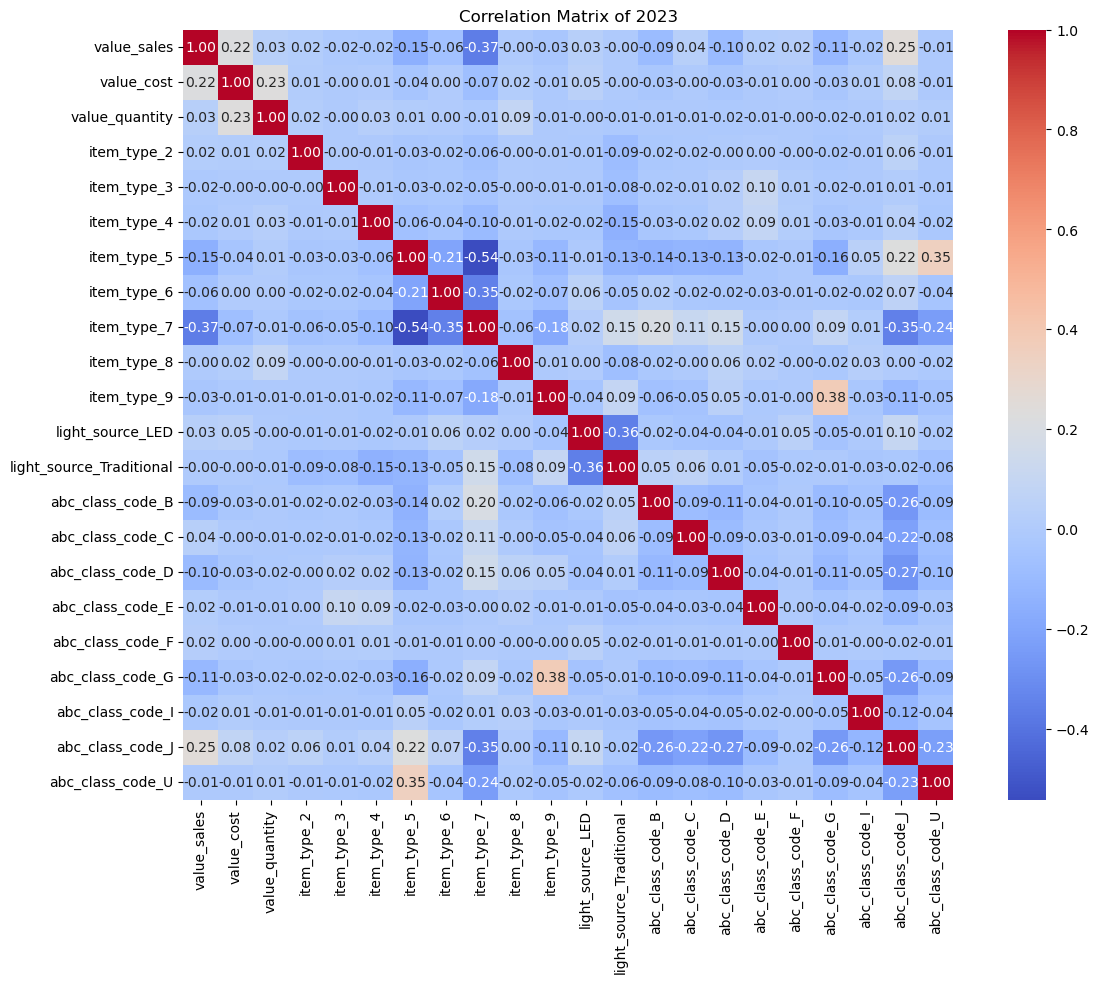

In [37]:
## Calculate the correlation matrix
corr_23 = df_2023_ref.corr()
corr_24 = df_2024_ref.corr()

## Draw correlation heatmap for 2023
plt.figure(figsize = (14, 10))
sns.heatmap(corr_23, annot = True, cmap = 'coolwarm', fmt = ".2f", square = True)
plt.title("Correlation Matrix of 2023")
plt.show()

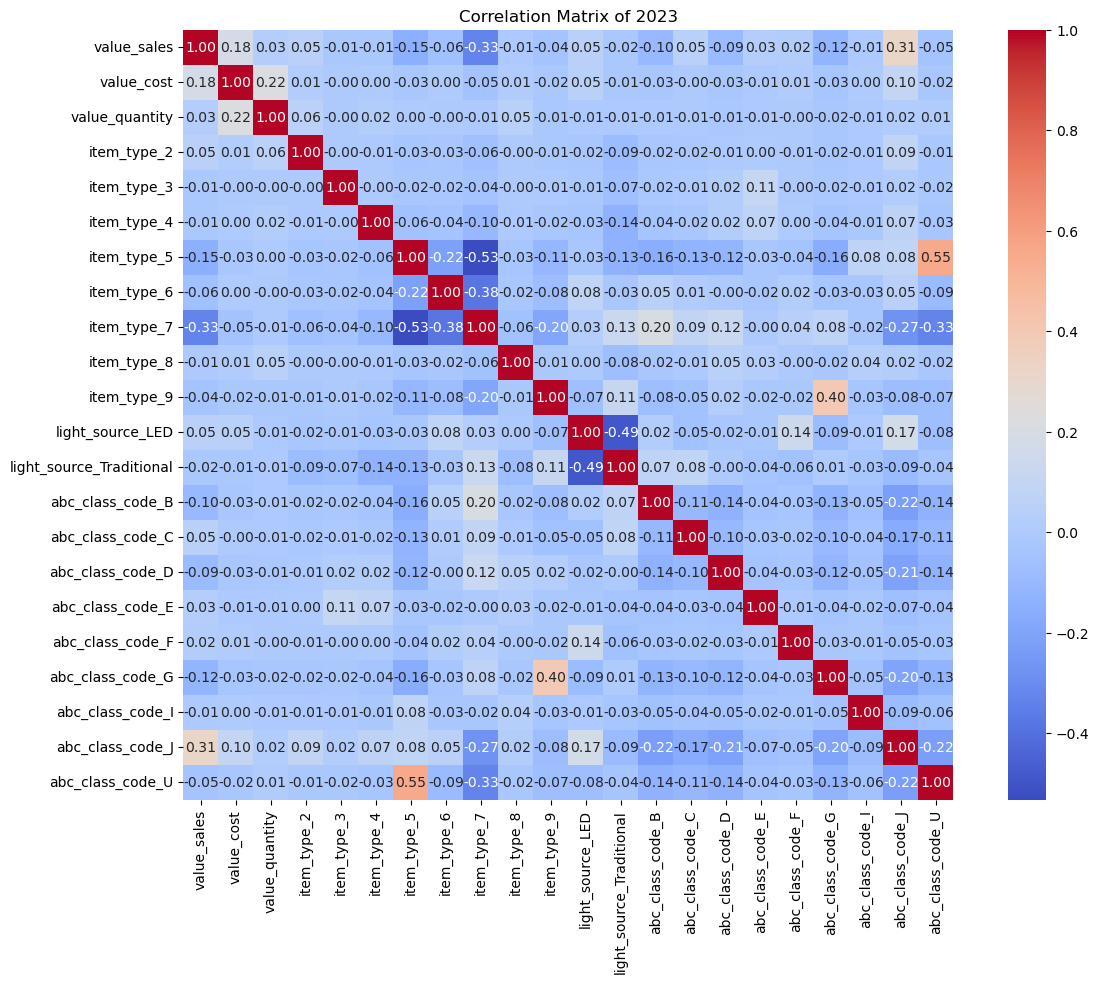

In [38]:
## Draw correlation heatmap for 2024
plt.figure(figsize = (14, 10))
sns.heatmap(corr_24, annot = True, cmap = 'coolwarm', fmt = ".2f", square = True)
plt.title("Correlation Matrix of 2023")
plt.show()

In [39]:
## Select independent variables
selected_vars = ['value_cost', 'value_quantity'] 
  #Add dummy variables
selected_vars += [col for col in df_2023_ref.columns if col.startswith('item_type_') 
                  or col.startswith('light_source_') 
                  or col.startswith('abc_class_code_')]

In [40]:
## Extract the independent variable matrix X for 2023
X_23 = df_2023_ref[selected_vars]
## Extract the dependent variable y for 2023
y_23 = df_2023_ref['value_sales']

## Add constant
X_23 = sm.add_constant(X_23)

## Convert the dummy variables to int format
bool_cols = X_23.select_dtypes(include=["bool"]).columns
X_23[bool_cols] = X_23[bool_cols].astype(int)

## Calculate vif for 2023
vif_data_23 = pd.DataFrame()
vif_data_23["Variable"] = X_23.columns
vif_data_23["VIF"] = [variance_inflation_factor(X_23.values, i)
                   for i in range(X_23.shape[1])]
print(vif_data_23)

                    Variable        VIF
0                      const  23.205681
1                 value_cost   1.099308
2             value_quantity   1.070249
3                item_type_2   1.045653
4                item_type_3   1.041522
5                item_type_4   1.141902
6                item_type_5   2.792274
7                item_type_6   2.042586
8                item_type_7   3.661188
9                item_type_8   1.056568
10               item_type_9   1.617379
11          light_source_LED   1.211594
12  light_source_Traditional   1.289460
13          abc_class_code_B   1.527899
14          abc_class_code_C   1.413821
15          abc_class_code_D   1.587764
16          abc_class_code_E   1.111368
17          abc_class_code_F   1.006115
18          abc_class_code_G   1.704659
19          abc_class_code_I   1.152120
20          abc_class_code_J   2.774335
21          abc_class_code_U   1.722497


In [41]:
## Extract the independent variable matrix X for 2024
X_24 = df_2024_ref[selected_vars]
## Extract the dependent variable y for 2024
y_24 = df_2024_ref['value_sales']

## Add constant
X_24 = sm.add_constant(X_24)

## Convert the dummy variables to int format
bool_cols = X_24.select_dtypes(include=["bool"]).columns
X_24[bool_cols] = X_24[bool_cols].astype(int)

## Calculate vif for 2024
vif_data_24 = pd.DataFrame()
vif_data_24["Variable"] = X_24.columns
vif_data_24["VIF"] = [variance_inflation_factor(X_24.values, i)
                   for i in range(X_24.shape[1])]
print(vif_data_24)

                    Variable        VIF
0                      const  25.160865
1                 value_cost   1.078207
2             value_quantity   1.059669
3                item_type_2   1.063249
4                item_type_3   1.040995
5                item_type_4   1.165151
6                item_type_5   3.322586
7                item_type_6   2.421323
8                item_type_7   4.206429
9                item_type_8   1.055700
10               item_type_9   1.769798
11          light_source_LED   1.502620
12  light_source_Traditional   1.523715
13          abc_class_code_B   1.567482
14          abc_class_code_C   1.391176
15          abc_class_code_D   1.546449
16          abc_class_code_E   1.100454
17          abc_class_code_F   1.059066
18          abc_class_code_G   1.702175
19          abc_class_code_I   1.138647
20          abc_class_code_J   2.379125
21          abc_class_code_U   2.202358


In [42]:
## Fit the multiple regression model 2023
model_23 = sm.OLS(y_23, X_23).fit()

print(model_23.summary())

                            OLS Regression Results                            
Dep. Variable:            value_sales   R-squared:                       0.861
Model:                            OLS   Adj. R-squared:                  0.861
Method:                 Least Squares   F-statistic:                 3.010e+05
Date:                Sun, 02 Nov 2025   Prob (F-statistic):               0.00
Time:                        16:13:40   Log-Likelihood:            -6.2664e+06
No. Observations:             1024344   AIC:                         1.253e+07
Df Residuals:                 1024322   BIC:                         1.253e+07
Df Model:                          21                                         
Covariance Type:            nonrobust                                         
                               coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------
const                   

In [43]:
## Fit the multiple regression model 2024
model_24 = sm.OLS(y_24, X_24).fit()

print(model_24.summary())

                            OLS Regression Results                            
Dep. Variable:            value_sales   R-squared:                       0.863
Model:                            OLS   Adj. R-squared:                  0.863
Method:                 Least Squares   F-statistic:                 2.835e+05
Date:                Sun, 02 Nov 2025   Prob (F-statistic):               0.00
Time:                        16:13:40   Log-Likelihood:            -5.8211e+06
No. Observations:              943812   AIC:                         1.164e+07
Df Residuals:                  943790   BIC:                         1.164e+07
Df Model:                          21                                         
Covariance Type:            nonrobust                                         
                               coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------
const                   

#### both model_23 and model_24 got p < 0.0001 reject H0, *R^2* > 0.86 support H1.

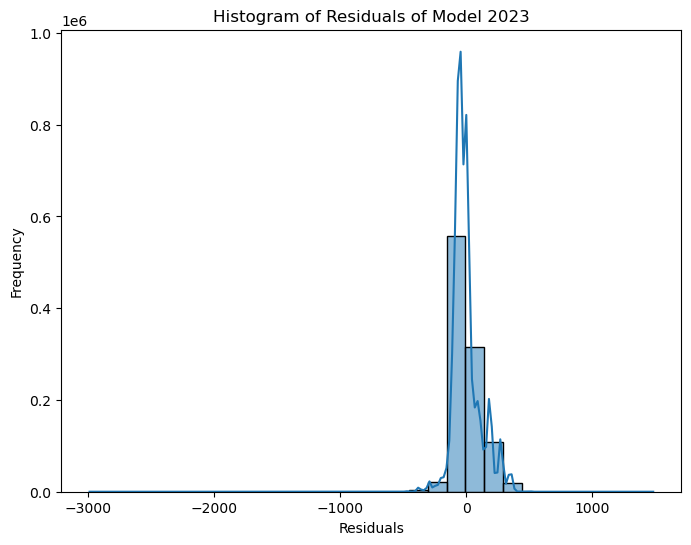

In [44]:
# Get the residuals of 2023
residuals_23 = model_23.resid


# Histogram of residuals 2023
plt.figure(figsize = (8, 6))
sns.histplot(residuals_23, kde = True, bins = 30)
plt.title('Histogram of Residuals of Model 2023')
plt.xlabel('Residuals')
plt.ylabel('Frequency')
plt.show()

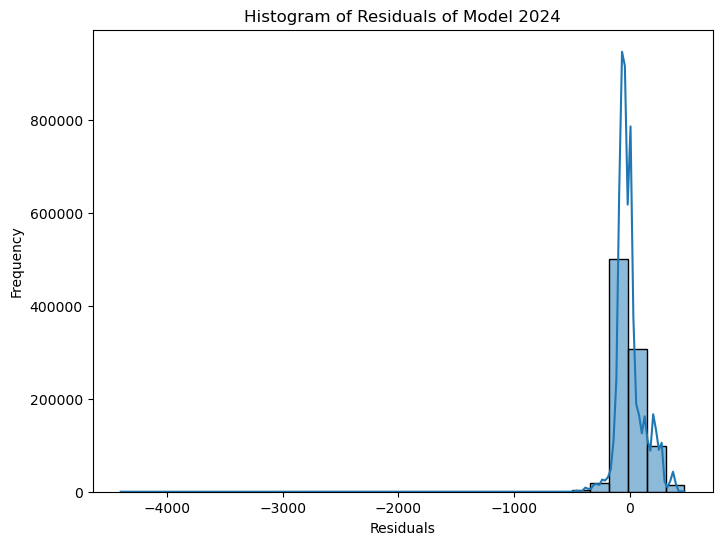

In [45]:
# Get the residuals of 2024
residuals_24 = model_24.resid


# Histogram of residuals 2024
plt.figure(figsize = (8, 6))
sns.histplot(residuals_24, kde = True, bins = 30)
plt.title('Histogram of Residuals of Model 2024')
plt.xlabel('Residuals')
plt.ylabel('Frequency')
plt.show()

#### The residuals of the two models are concentrated around 0, the model predictions are generally close to the actual sales data. The 2023 residuals are slightly to the right, and the 2024 residuals are slightly to the left, both with longer tails indicate larger fluctuations.

<Figure size 800x600 with 0 Axes>

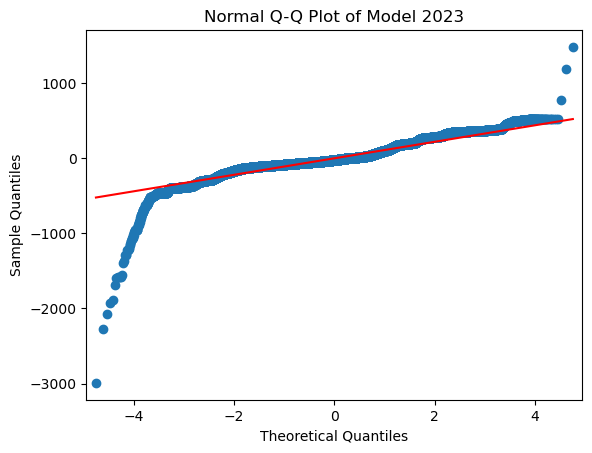

In [46]:
## Q-Q plot of the residuals 2023
plt.figure(figsize = (8, 6))
sm.qqplot(residuals_23, line = 's')
plt.title("Normal Q-Q Plot of Model 2023")

plt.show()

<Figure size 800x600 with 0 Axes>

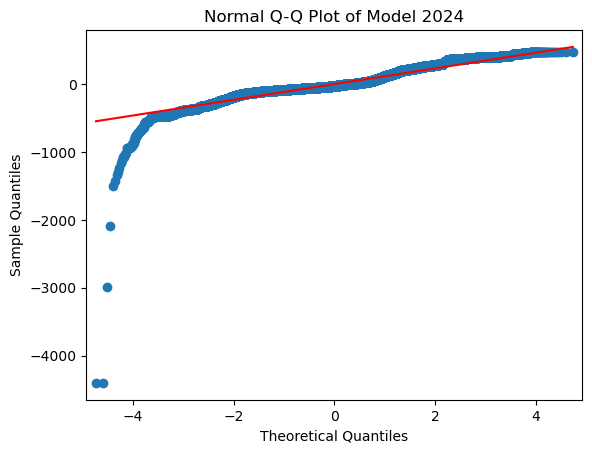

In [47]:
## Q-Q plot of the residuals 2024
plt.figure(figsize = (8, 6))
sm.qqplot(residuals_24, line = 's')
plt.title("Normal Q-Q Plot of Model 2024")

plt.show()

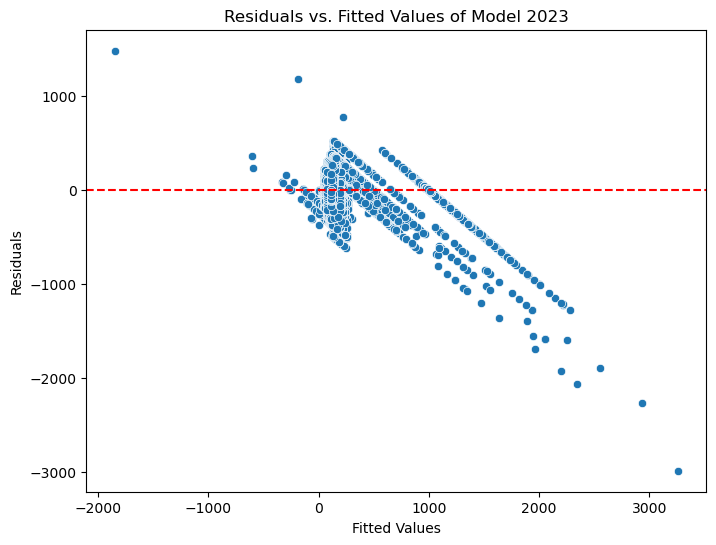

In [48]:
# Get fitted values of 2023
fitted_vals_23 = model_23.fittedvalues

# Scatter plot of residuals vs. fitted values 
plt.figure(figsize = (8, 6))
sns.scatterplot(x = fitted_vals_23, y=residuals_23)
plt.axhline(0, color = 'red', linestyle = '--')
plt.title('Residuals vs. Fitted Values of Model 2023')
plt.xlabel('Fitted Values')
plt.ylabel('Residuals')
plt.show()

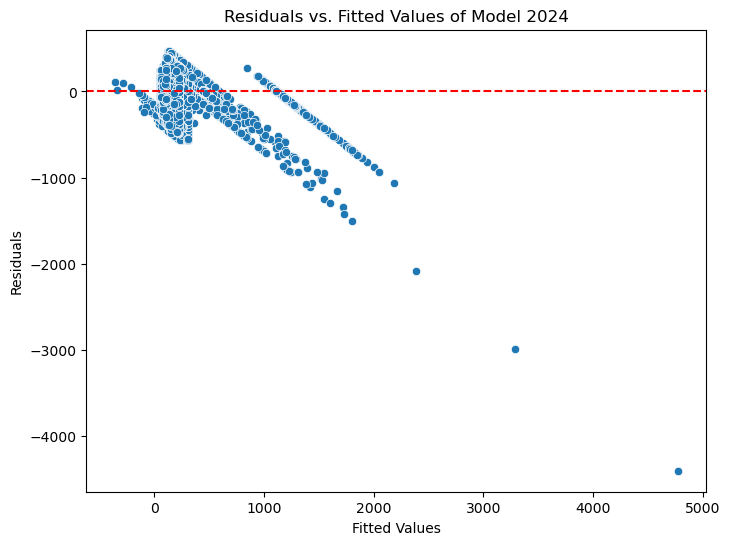

In [49]:
# Get fitted values of 2024
fitted_vals_24 = model_24.fittedvalues

# Scatter plot of residuals vs. fitted values
plt.figure(figsize = (8, 6))
sns.scatterplot(x = fitted_vals_24, y=residuals_24)
plt.axhline(0, color = 'red', linestyle = '--')
plt.title('Residuals vs. Fitted Values of Model 2024')
plt.xlabel('Fitted Values')
plt.ylabel('Residuals')
plt.show()

#### The residual plot shows that the residuals are distributed around the 0 line, but as the fitted value increases, the residuals tend to be negative, indicating that the model tends to underestimate high-selling products, especially in 2024.